In [6]:
from pathlib import Path

BASE_DIR = Path.cwd().parent.parent  
results_path = BASE_DIR / "results"

In [7]:
import jsonlines, json, glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
from scipy import stats
from pathlib import Path

# experiment definitions
EXPERIMENTS = {
    # No domain knowledge 
    "E1: No domain knowledge": {
        "color": "#BD9B3D",        
        "linestyle": "-",
        "runs": sorted(glob.glob(str(results_path / "without_domain_knowledge/*/log.jsonl"))),
    },
    "E3: No Domain + exemplar-injection": {
        "color": "#FF0000",        
        "linestyle": "-",
        "runs": sorted(glob.glob(str(results_path /"mutation_5_runs_elitism_on/*/log.jsonl"))),
    },
    "E4: No Domain + warm start": {
        "color": "#FB7507",        
        "linestyle": "-",
        "runs": sorted(glob.glob(str(results_path /"warm_start_5_runs/*/log.jsonl"))),
    },

    # Domain knowledge 
    "E2: Domain knowledge": {
        "color": "#06D65D",        
        "linestyle": "dotted",
        "runs": sorted(glob.glob(str(results_path /"domain_knowledge/*/log.jsonl"))),
    },
    "E5: Domain + exemplar-injection": {
        "color": "#3A86FF",
        "linestyle": "dotted",
        "runs": sorted(glob.glob(str(results_path /"5_runs_mutation_prompts_WITH_DOMAIN_KNOWLEDGE/*/log.jsonl"))),
    },
    "E6: Domain + warm start": {
        "color": "#9B5DE5",        
        "linestyle": "dotted",
        "runs": sorted(glob.glob(str(results_path /"warm_start/*/log.jsonl"))),
    },
}
BUDGET = 200

In [8]:
def load_run(path):
    """Return list of fitness values in evaluation order from a log.jsonl."""
    records = []
    with jsonlines.open(path) as reader:
        for obj in reader:
            if isinstance(obj, list):        # population snapshot
                for ind in obj:
                    records.append(ind.get("fitness", np.nan))
            elif isinstance(obj, dict):    # individual entry
                records.append(obj.get("fitness", np.nan))
    return np.array(records[:BUDGET], dtype=float)

def best_so_far(arr):
    """Running maximum (assumes maximisation)."""
    out = np.full_like(arr, np.nan)
    best = -np.inf
    for i, v in enumerate(arr):
        if np.isfinite(v) and v > best:
            best = v
        out[i] = best if np.isfinite(best) else np.nan
    return out

# load everything
data = {}
for label, cfg in EXPERIMENTS.items():
    runs = [best_so_far(load_run(p)) for p in cfg["runs"]]
    # pad shorter runs with their final value
    padded = [np.pad(r, (0, BUDGET - len(r)), "edge")
              if len(r) < BUDGET else r for r in runs]
    data[label] = np.array(padded)  # shape (n_runs, BUDGET)

print({k: v.shape for k, v in data.items()})

{'E1: No domain knowledge': (5, 200), 'E3: No Domain + exemplar-injection': (5, 200), 'E4: No Domain + warm start': (5, 200), 'E2: Domain knowledge': (5, 200), 'E5: Domain + exemplar-injection': (5, 200), 'E6: Domain + warm start': (3, 200)}


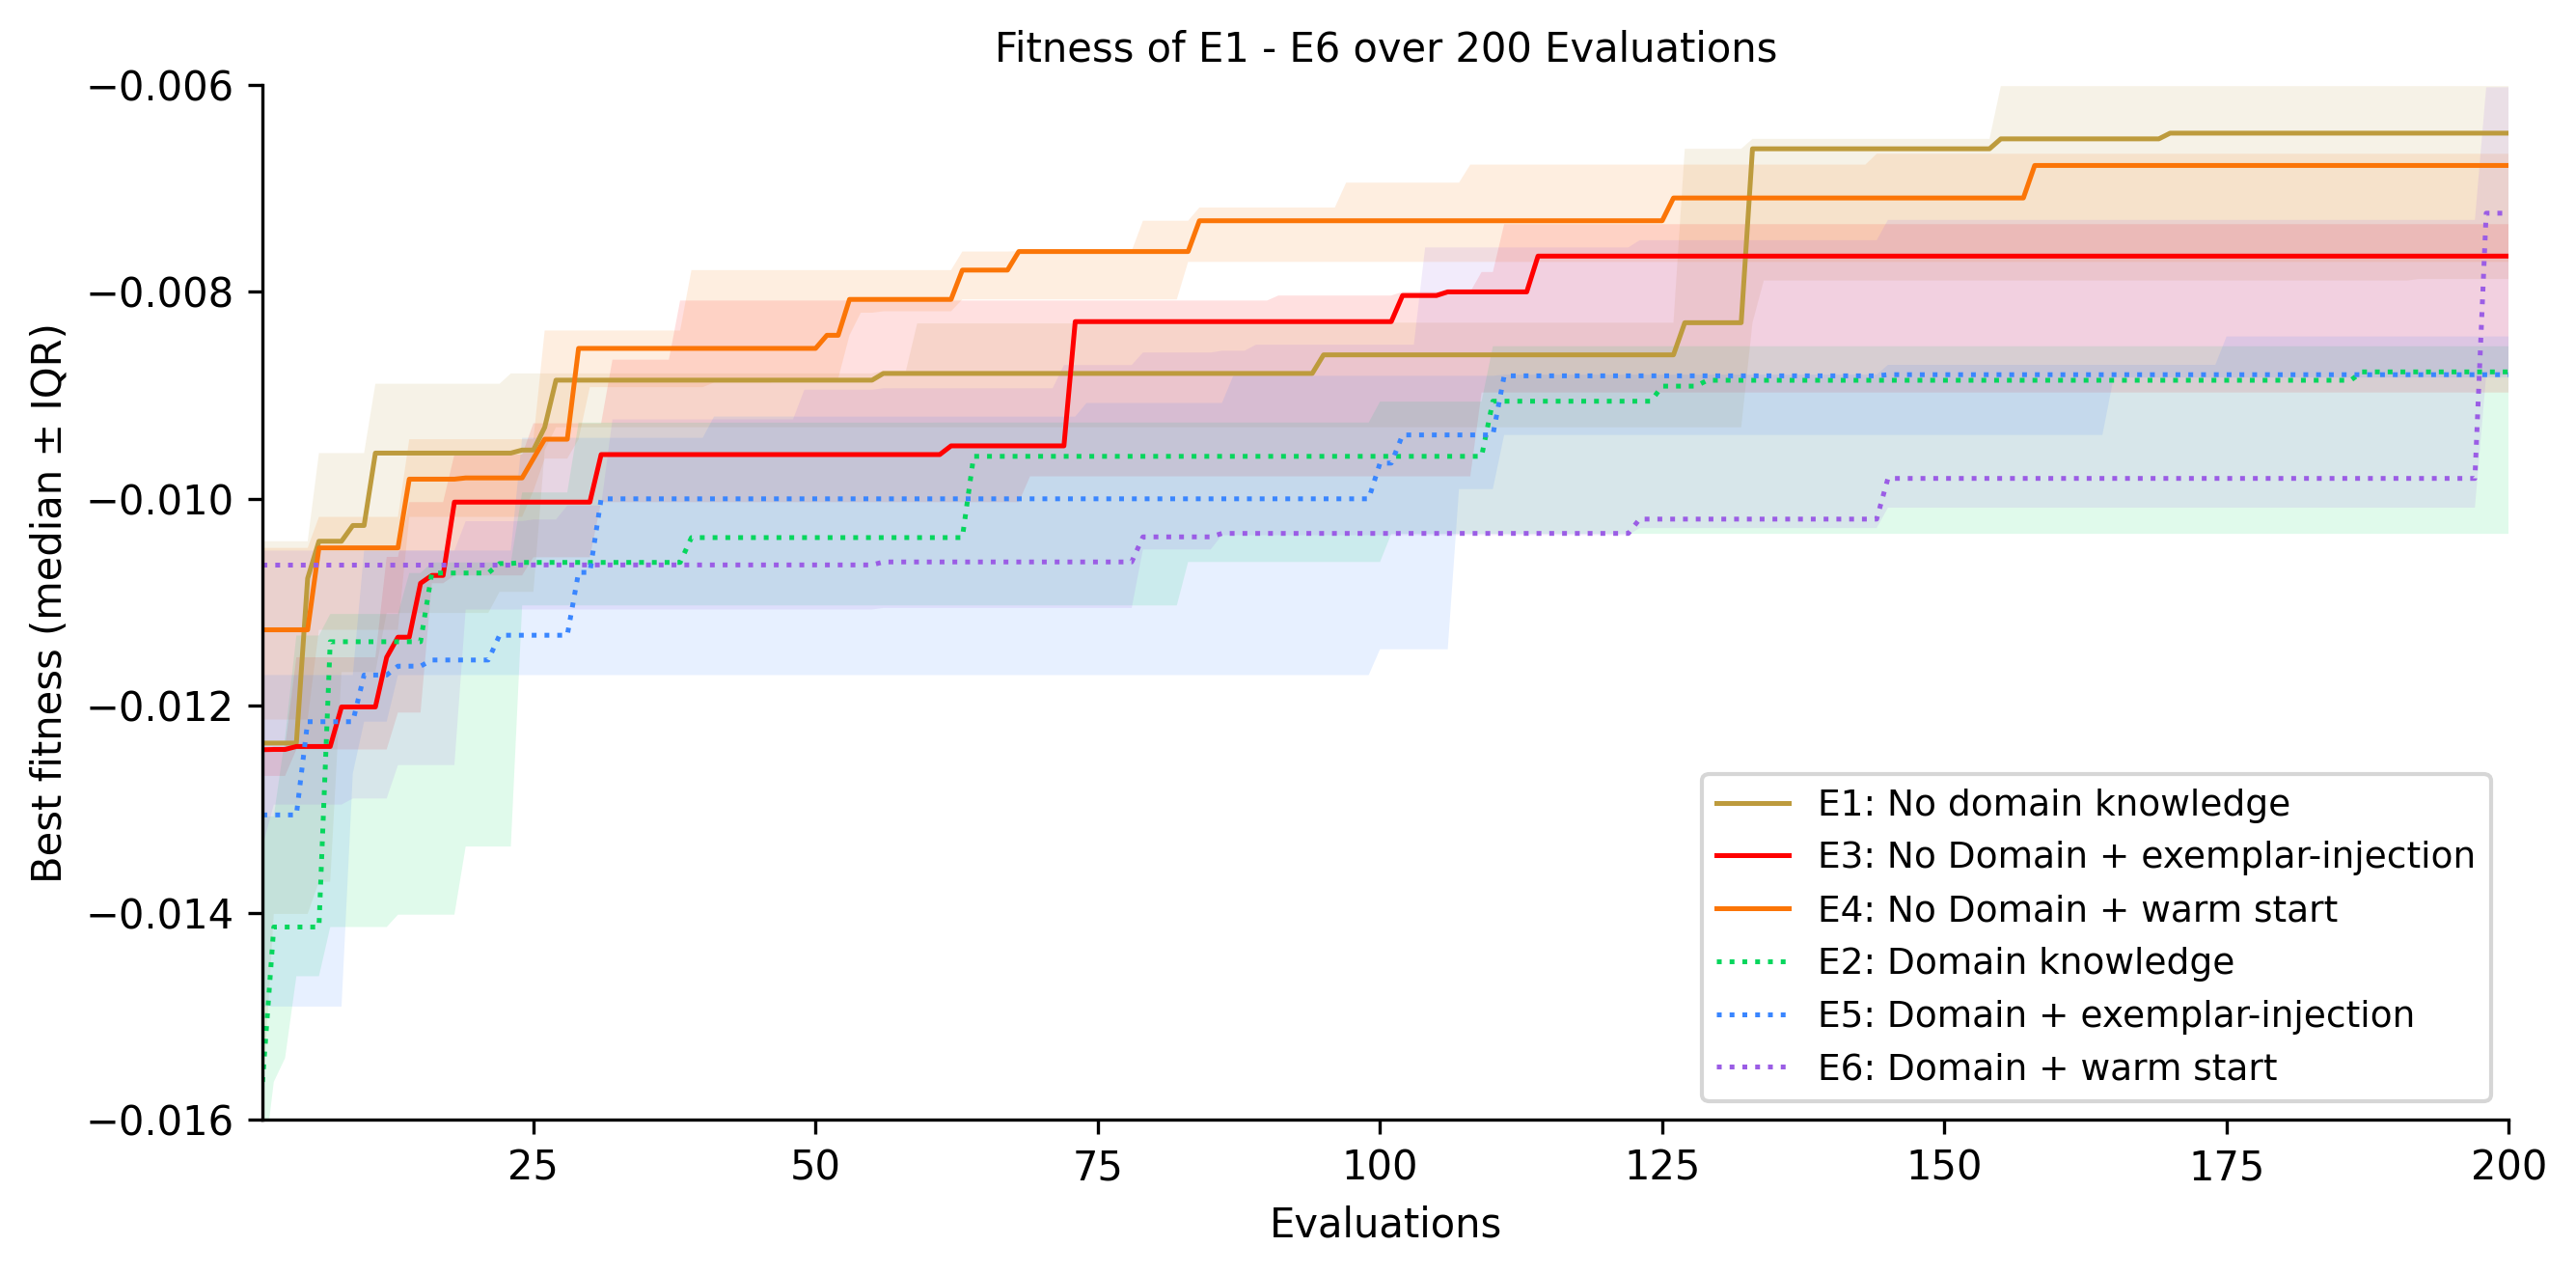

In [9]:
SENTINEL = -1e9


fig, ax = plt.subplots(figsize=(9, 4.5), dpi=300)
x = np.arange(1, BUDGET + 1)

for label, cfg in [(l, c) for l, c in EXPERIMENTS.items() if l in ("E1: No domain knowledge", "E2: Domain knowledge", "E3: No Domain + exemplar-injection", "E4: No Domain + warm start", "E5: Domain + exemplar-injection", "E6: Domain + warm start")]:
    mat = data[label].copy().astype(float)
    if len(mat) == 0: continue

    # mask out inf and sentinel values (remove errors)
    mat[~np.isfinite(mat)] = np.nan
    mat[np.isclose(mat, SENTINEL, rtol=1e-3)] = np.nan

    # forward fill NaNs with the first finite value for each run
    for i in range(mat.shape[0]):
        finite_mask = np.isfinite(mat[i])
        if np.any(finite_mask):
            first_finite_idx = np.where(finite_mask)[0][0]
            mat[i, :first_finite_idx] = mat[i, first_finite_idx]

    med = np.nanmedian(mat, axis=0)
    q25 = np.nanpercentile(mat, 25, axis=0)
    q75 = np.nanpercentile(mat, 75, axis=0)

    ax.plot(x, med, label=label, color=cfg["color"],
            linestyle=cfg["linestyle"], linewidth=1.2)
    ax.fill_between(x, q25, q75, color=cfg["color"], alpha=0.12,
                    edgecolor='none', linewidth=0)

ax.set_title("Fitness of E1 - E6 over 200 Evaluations", fontsize=10)
ax.set_xlabel("Evaluations"); ax.set_ylabel("Best fitness (median ± IQR)")
ax.set_xlim(1, BUDGET); ax.legend(fontsize=9)
ax.set_ylim(-0.016, -0.006)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout(); plt.show()

In [10]:
rows = []
for label, cfg in EXPERIMENTS.items():
    mat = data[label]
    finals = mat[:, -1]  # best fitness at end of budget per run
    rows.append({
        "Experiment": label,
        "Runs": len(mat),
        "Median final": round(np.nanmedian(finals), 4),
        "IQR": round(np.nanpercentile(finals, 75)
                       - np.nanpercentile(finals, 25), 4),
        "Best": round(np.nanmax(finals), 4),
        "Worst": round(np.nanmin(finals), 4),
    })

df = pd.DataFrame(rows).set_index("Experiment")
display(df)

,Runs,Median final,IQR,Best,Worst
Experiment,,,,,
E1: No domain knowledge,5,-0.0065,0.0019,-0.0045,-0.0097
E3: No Domain + exemplar-injection,5,-0.0077,0.0016,-0.0045,-0.0101
E4: No Domain + warm start,5,-0.0068,0.0010,-0.0026,-0.0077
E2: Domain knowledge,5,-0.0088,0.0018,-0.0044,-0.0106
E5: Domain + exemplar-injection,5,-0.0088,0.0004,-0.0029,-0.0110
E6: Domain + warm start,3,-0.0072,0.0028,-0.0048,-0.0104


In [11]:
# Pairwise Mann-Whitney U, corrected with Holm-Bonferroni
# uses final-budget fitness values per run
from itertools import combinations

labels = list(EXPERIMENTS.keys())
pairs, pvals = [], []
for a, b in combinations(labels, 2):
    fa = data[a][:, -1][~np.isnan(data[a][:, -1])]
    fb = data[b][:, -1][~np.isnan(data[b][:, -1])]
    _, p = stats.mannwhitneyu(fa, fb, alternative="two-sided")
    pairs.append((a, b)); pvals.append(p)

# Holm-Bonferroni correction
order = np.argsort(pvals)
corrected = np.ones(len(pvals))
for rank, idx in enumerate(order):
    corrected[idx] = min(1.0, pvals[idx] * (len(pvals) - rank))

stat_rows = []
for (a, b), raw, adj in zip(pairs, pvals, corrected):
    stat_rows.append({
        "Pair": f"{a.split(':')[0]} vs {b.split(':')[0]}",
        "p (raw)": f"{raw:.4f}",
        "p (Holm)": f"{adj:.4f}",
        "Significant": "yes" if adj < 0.05 else "no",
    })

display(pd.DataFrame(stat_rows))

,Pair,p (raw),p (Holm),Significant
0,E1 vs E3,0.5476,1.0000,no
1,E1 vs E4,1.0000,1.0000,no
2,E1 vs E2,0.3095,1.0000,no
3,E1 vs E5,0.4206,1.0000,no
4,E1 vs E6,0.7857,1.0000,no
5,E3 vs E4,0.4206,1.0000,no
6,E3 vs E2,0.5476,1.0000,no
7,E3 vs E5,0.8413,1.0000,no
8,E3 vs E6,1.0000,1.0000,no
9,E4 vs E2,0.0952,1.0000,no


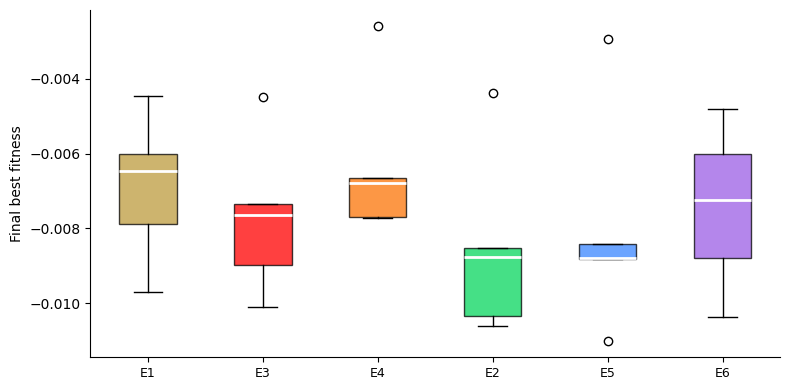

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
finals_list = [data[l][:, -1] for l in EXPERIMENTS]
colors      = [cfg["color"] for cfg in EXPERIMENTS.values()]

bp = ax.boxplot(finals_list, patch_artist=True, medianprops=dict(color="white", linewidth=2))
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color); patch.set_alpha(0.75)

ax.set_xticks(range(1, len(EXPERIMENTS) + 1))
ax.set_xticklabels([l.split(":")[0] for l in EXPERIMENTS], fontsize=9)
ax.set_ylabel("Final best fitness")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
plt.tight_layout(); plt.show()

## Testing on a marginally larger model 

In [13]:
import json
import re
import jsonlines
import glob
import numpy as np
import pandas as pd

FAILURE_THRESHOLD = -1e6

EXPERIMENT_LOGS = {
    "E1": sorted(glob.glob(str(results_path / "minor_testing_with_35b_E1/*/log.jsonl"))),
    "E2": sorted(glob.glob(str(results_path / "minor_testing_with_35b_E2/*/log.jsonl"))),
    "E3": sorted(glob.glob(str(results_path / "minor_testing_with_35b_E3/*/log.jsonl"))),
    "E4": sorted(glob.glob(str(results_path / "minor_testing_with_35b_E4/*/log.jsonl"))),
}

K_TO_DIMENSION_LABEL = {
    2: 4,
    3: 6,
    5: 10,
    10: 20,
}

def safe_float(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return np.nan

def safe_int(x):
    try:
        return int(float(x))
    except (TypeError, ValueError):
        return np.nan

def extract_dim_from_problem_name(problem_name):
    if not isinstance(problem_name, str):
        return np.nan

    match = re.search(r"dim=(\d+)", problem_name)

    if match:
        return int(match.group(1))

    return np.nan

# find the key and matching val
def find_key_recursive(obj, target_key):
    if isinstance(obj, dict):
        if target_key in obj:
            return obj[target_key]

        for value in obj.values():
            found = find_key_recursive(value, target_key)
            if found is not None:
                return found

    elif isinstance(obj, list):
        for item in obj:
            found = find_key_recursive(item, target_key)
            if found is not None:
                return found

    return None

# parse json
def parse_possible_json_string(value):
    if isinstance(value, str):
        value_stripped = value.strip()

        if (
            value_stripped.startswith("{")
            or value_stripped.startswith("[")
        ):
            try:
                return json.loads(value_stripped)
            except json.JSONDecodeError:
                return value

    return value

# ensure perf data becomes a list of dicts
def normalize_performance_data(performance_data):
    performance_data = parse_possible_json_string(performance_data)

    if isinstance(performance_data, dict):
        return [performance_data]

    if isinstance(performance_data, list):
        return [
            item for item in performance_data
            if isinstance(item, dict)
        ]

    return []

# extract performance from Qwen3.6:35b logs
def extract_qwen_performance_trace(log_paths, failure_threshold=FAILURE_THRESHOLD, debug=False):

    rows = []
    missing_perf_count = 0
    total_valid_individuals = 0

    for run_idx, path in enumerate(log_paths):
        call_idx = 0

        with jsonlines.open(path) as reader:
            for line_idx, obj in enumerate(reader):
                items = obj if isinstance(obj, list) else [obj]

                for item_idx, ind in enumerate(items):
                    # parse the whole item 
                    ind = parse_possible_json_string(ind)

                    if not isinstance(ind, dict):
                        continue

                    fitness = safe_float(find_key_recursive(ind, "fitness"))
                    code = find_key_recursive(ind, "code")
                    name = find_key_recursive(ind, "name")
                    description = find_key_recursive(ind, "description")

                    if not (
                        code
                        and np.isfinite(fitness)
                        and fitness > failure_threshold
                    ):
                        continue

                    total_valid_individuals += 1

                    performance_data_raw = find_key_recursive(ind, "performance_data")
                    performance_data = normalize_performance_data(performance_data_raw)

                    if not performance_data:
                        missing_perf_count += 1

                        if debug and missing_perf_count <= 3:
                            print("\nNo performance_data found for item:")
                            print(f"path={path}")
                            print(f"line_idx={line_idx}, item_idx={item_idx}")
                            print("top-level keys:", list(ind.keys()))
                            print("nested candidate keys:")
                            print_all_keys(ind, max_depth=3)

                        call_idx += 1
                        continue

                    for perf in performance_data:
                        fid = safe_int(perf.get("fid", np.nan))
                        iid = safe_int(perf.get("iid", np.nan))
                        k = safe_int(perf.get("k", np.nan))

                        problem_name = perf.get("problem_name", "")
                        dim = extract_dim_from_problem_name(problem_name)

                        if pd.isna(dim) and not pd.isna(k):
                            dim = K_TO_DIMENSION_LABEL.get(int(k), int(k))

                        baseline_mse = safe_float(perf.get("baseline_mse", np.nan))
                        auc_imp = safe_float(perf.get("auc_imp", np.nan))

                        # if auc_imp = baseline_mse - algorithm_mse:
                        mse = (
                            baseline_mse - auc_imp
                            if np.isfinite(baseline_mse) and np.isfinite(auc_imp)
                            else np.nan
                        )

                        if pd.isna(fid) or pd.isna(k):
                            continue

                        rows.append({
                            "run": run_idx,
                            "call_idx": call_idx,
                            "fitness": fitness,
                            "name": name,
                            "description": description,
                            "path": path,
                            "fid": int(fid),
                            "iid": int(iid) if not pd.isna(iid) else np.nan,
                            "k": int(k),
                            "dimension_label": int(dim) if not pd.isna(dim) else np.nan,
                            "problem_name": problem_name,
                            "baseline_mse": baseline_mse,
                            "auc_imp": auc_imp,
                            "mse": mse,
                        })

                    call_idx += 1

    df = pd.DataFrame(rows)

    if debug:
        print(f"\nTotal valid individuals: {total_valid_individuals}")
        print(f"Individuals missing performance_data: {missing_perf_count}")
        print(f"Extracted performance rows: {len(df)}")

    if df.empty:
        return df

    individual_best = (
        df[["run", "call_idx", "fitness"]]
        .drop_duplicates()
        .sort_values(["run", "call_idx"])
    )

    individual_best["best_so_far"] = (
        individual_best
        .groupby("run")["fitness"]
        .cummax()
    )

    df = df.merge(
        individual_best[["run", "call_idx", "best_so_far"]],
        on=["run", "call_idx"],
        how="left"
    )

    return df


def print_all_keys(obj, prefix="", depth=0, max_depth=3):
    """
    Debug helper to inspect where performance_data is stored.
    """
    if depth > max_depth:
        return

    if isinstance(obj, dict):
        for key, value in obj.items():
            print(f"{prefix}{key}: {type(value).__name__}")

            if isinstance(value, (dict, list)):
                print_all_keys(
                    value,
                    prefix=prefix + "  ",
                    depth=depth + 1,
                    max_depth=max_depth
                )

    elif isinstance(obj, list):
        print(f"{prefix}[list with {len(obj)} items]")

        if len(obj) > 0:
            print_all_keys(
                obj[0],
                prefix=prefix + "  ",
                depth=depth + 1,
                max_depth=max_depth
            )

# collect traces 
trace_rows = []

for exp_name, paths in EXPERIMENT_LOGS.items():
    df = extract_qwen_performance_trace(paths)

    if df.empty:
        print(f"No valid performance rows for {exp_name}")
        continue

    df["experiment"] = exp_name
    trace_rows.append(df)

qwen_trace = pd.concat(trace_rows, ignore_index=True)

qwen_trace.head()

,run,call_idx,fitness,name,description,path,fid,iid,k,dimension_label,problem_name,baseline_mse,auc_imp,mse,best_so_far,experiment
0,0,0,-0.026505,AdaptiveMomentumDifferentialEvolution,Momentum-driven adaptive perturbation with eli...,c:\Users\Anna Michelle\Documents\GitHub\Thesis...,1,1,2,4,<RealSingleObjectiveProblem 1. Cluster_breast_...,0.044068,-0.044230,0.088298,-0.026505,E1
1,0,0,-0.026505,AdaptiveMomentumDifferentialEvolution,Momentum-driven adaptive perturbation with eli...,c:\Users\Anna Michelle\Documents\GitHub\Thesis...,1,1,3,6,<RealSingleObjectiveProblem 1. Cluster_breast_...,0.029825,-0.034406,0.064231,-0.026505,E1
2,0,0,-0.026505,AdaptiveMomentumDifferentialEvolution,Momentum-driven adaptive perturbation with eli...,c:\Users\Anna Michelle\Documents\GitHub\Thesis...,1,1,5,10,<RealSingleObjectiveProblem 1. Cluster_breast_...,0.014901,-0.017017,0.031918,-0.026505,E1
3,0,0,-0.026505,AdaptiveMomentumDifferentialEvolution,Momentum-driven adaptive perturbation with eli...,c:\Users\Anna Michelle\Documents\GitHub\Thesis...,1,1,10,20,<RealSingleObjectiveProblem 1. Cluster_breast_...,0.004568,-0.018269,0.022837,-0.026505,E1
4,0,0,-0.026505,AdaptiveMomentumDifferentialEvolution,Momentum-driven adaptive perturbation with eli...,c:\Users\Anna Michelle\Documents\GitHub\Thesis...,2,1,2,4,<RealSingleObjectiveProblem 2. Cluster_diabete...,0.029030,-0.022934,0.051965,-0.026505,E1


In [14]:
print(qwen_trace.columns)

print(
    qwen_trace[
        [
            "experiment",
            "call_idx",
            "fitness",
            "fid",
            "iid",
            "k",
            "dimension_label",
            "baseline_mse",
            "auc_imp",
            "mse",
        ]
    ].head(20)
)

print("\nCounts per experiment:")
print(qwen_trace.groupby("experiment").size())

print("\nCounts per FID and dimension:")
print(
    qwen_trace
    .groupby(["fid", "dimension_label"])
    .size()
    .unstack(fill_value=0)
)

Index(['run', 'call_idx', 'fitness', 'name', 'description', 'path', 'fid',
       'iid', 'k', 'dimension_label', 'problem_name', 'baseline_mse',
       'auc_imp', 'mse', 'best_so_far', 'experiment'],
      dtype='object')
   experiment  call_idx   fitness  fid  iid   k  dimension_label  \
0          E1         0 -0.026505    1    1   2                4   
1          E1         0 -0.026505    1    1   3                6   
2          E1         0 -0.026505    1    1   5               10   
3          E1         0 -0.026505    1    1  10               20   
4          E1         0 -0.026505    2    1   2                4   
5          E1         0 -0.026505    2    1   3                6   
6          E1         0 -0.026505    2    1   5               10   
7          E1         0 -0.026505    2    1  10               20   
8          E1         0 -0.026505    3    1   2                4   
9          E1         0 -0.026505    3    1   3                6   
10         E1         0 -0.026

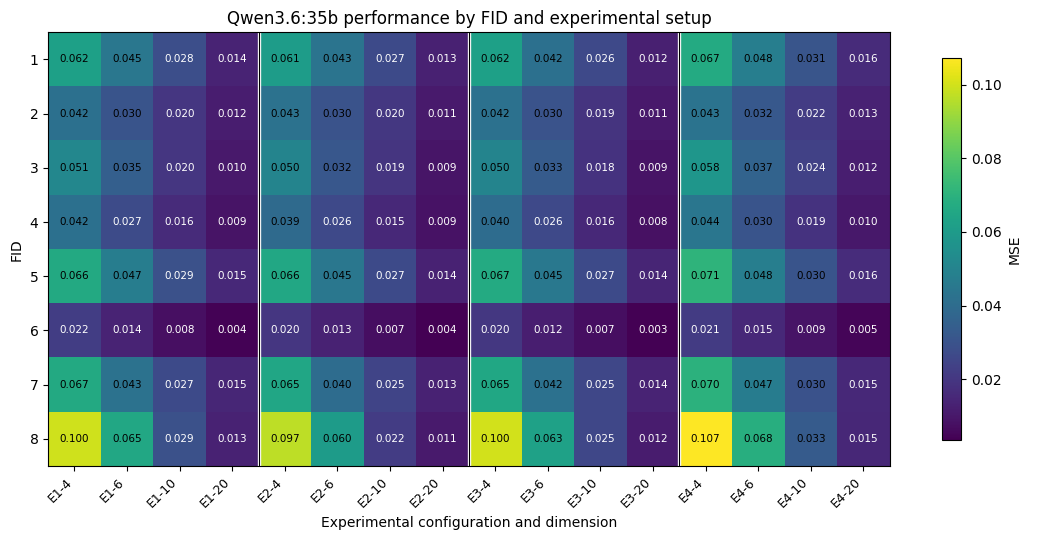

In [15]:
import matplotlib.pyplot as plt

EXPERIMENT_LOGS = {
    "E1": sorted(glob.glob(str(results_path / "minor_testing_with_35b_E1/*/log.jsonl"))),
    "E2": sorted(glob.glob(str(results_path / "minor_testing_with_35b_E2/*/log.jsonl"))),
    "E3": sorted(glob.glob(str(results_path / "minor_testing_with_35b_E3/*/log.jsonl"))),
    "E4": sorted(glob.glob(str(results_path / "minor_testing_with_35b_E4/*/log.jsonl"))),
    
}

def plot_qwen_recorded_performance_heatmap(qwen_trace, experiments=("E1", "E2", "E3", "E4"), value_col="auc_imp", agg="median", cmap=None, annotate=True, value_fmt="{:+.3f}", save_path=None,):
    # plot the collected qwern data from all experimental setups

    subset = qwen_trace[
        qwen_trace["experiment"].isin(experiments)
    ].copy()

    subset = subset[
        np.isfinite(subset[value_col])
        & subset["fid"].notna()
        & subset["dimension_label"].notna()
    ]

    if subset.empty:
        raise ValueError(f"No valid rows found for value_col={value_col}.")

    if agg == "median":
        grouped = (
            subset
            .groupby(["fid", "experiment", "dimension_label"], as_index=False)[value_col]
            .median()
        )
    elif agg == "mean":
        grouped = (
            subset
            .groupby(["fid", "experiment", "dimension_label"], as_index=False)[value_col]
            .mean()
        )
    else:
        raise ValueError("agg must be either 'median' or 'mean'.")

    grouped = grouped.rename(columns={value_col: "value"})

    dimension_order = sorted(grouped["dimension_label"].dropna().astype(int).unique())
    fid_order = sorted(grouped["fid"].dropna().astype(int).unique())

    ordered_column_labels = [
        f"{exp}-{dim}"
        for exp in experiments
        for dim in dimension_order
    ]

    grouped["column_label"] = (
        grouped["experiment"].astype(str)
        + "-"
        + grouped["dimension_label"].astype(int).astype(str)
    )

    pivot = grouped.pivot(
        index="fid",
        columns="column_label",
        values="value"
    )

    pivot = pivot.reindex(index=fid_order, columns=ordered_column_labels)

    values = pivot.values.astype(float)

    if cmap is None:
        cmap = "RdBu" if value_col == "auc_imp" else "viridis"

    if value_col == "auc_imp":
        absmax = np.nanmax(np.abs(values))
        vmin, vmax = -absmax, absmax
        metric_label = "AUC improvement over baseline"
        better_label = "positive is better"
    elif value_col == "mse":
        vmin, vmax = np.nanmin(values), np.nanmax(values)
        metric_label = "MSE"
        better_label = ""
    else:
        vmin, vmax = np.nanmin(values), np.nanmax(values)
        metric_label = value_col
        better_label = ""

    fig_width = max(11, 0.70 * len(ordered_column_labels))
    fig_height = max(5.5, 0.50 * len(fid_order))

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    im = ax.imshow(
        values,
        aspect="auto",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax
    )

    ax.set_xticks(np.arange(len(ordered_column_labels)))
    ax.set_xticklabels(
        ordered_column_labels,
        rotation=45,
        ha="right",
        fontsize=9
    )

    ax.set_yticks(np.arange(len(fid_order)))
    ax.set_yticklabels(fid_order)

    ax.set_xlabel("Experimental configuration and dimension")
    ax.set_ylabel("FID")

    ax.set_title(
        "Qwen3.6:35b performance by FID and experimental setup"
    )

    # vertical separators between experiments
    n_dims = len(dimension_order)

    for split in range(1, len(experiments)):
        x = split * n_dims - 0.5
        ax.axvline(x, color="white", linewidth=2.4)
        ax.axvline(x, color="black", linewidth=0.8)



    # separator between seen FIDs and unseen FIDs
    if 8 in fid_order and 9 in fid_order:
        split_y = fid_order.index(9) - 0.5

        ax.axhline(split_y, color="white", linewidth=2.4)
        ax.axhline(split_y, color="black", linewidth=0.8)

        ax.text(
            -1.2,
            (fid_order.index(1) + fid_order.index(8)) / 2,
            "Seen FIDs",
            ha="right",
            va="center",
            fontsize=10,
            rotation=90
        )

        ax.text(
            -1.2,
            (fid_order.index(9) + fid_order.index(10)) / 2,
            "Unseen FIDs",
            ha="right",
            va="center",
            fontsize=10,
            rotation=90
        )

    if annotate:
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):
                value = values[i, j]

                if np.isfinite(value):
                    normed = (value - vmin) / (vmax - vmin) if vmax > vmin else 0.5
                    text_color = "white" if normed < 0.25 or normed >= 1.01 else "black"

                    ax.text(
                        j,
                        i,
                        value_fmt.format(value),
                        ha="center",
                        va="center",
                        fontsize=7.5,
                        color=text_color
                    )

    cbar = plt.colorbar(im, ax=ax, shrink=0.88)
    cbar.set_label(f"{metric_label}\n{better_label}")

    plt.tight_layout()

    if save_path is not None:
        plt.savefig(f"{save_path}.pdf", bbox_inches="tight")
        plt.savefig(f"{save_path}.png", dpi=300, bbox_inches="tight")

    plt.show()

    return pivot, grouped

# qwen_pivot_auc, qwen_grouped_auc = plot_qwen_recorded_performance_heatmap(
#     qwen_trace,
#     experiments=("E1", "E2", "E3", "E4"),
#     value_col="auc_imp",
#     agg="median",
#     cmap="viridis",
#     annotate=True,
#     value_fmt="{:+.3f}",
#     save_path="qwen35b_auc_imp_fid_experiment_dimension_heatmap"
# )

qwen_pivot_mse, qwen_grouped_mse = plot_qwen_recorded_performance_heatmap(
    qwen_trace,
    experiments=("E1", "E2", "E3", "E4"),
    value_col="mse",
    agg="median",
    cmap="viridis",
    annotate=True,
    value_fmt="{:.3f}",
    save_path=None
)

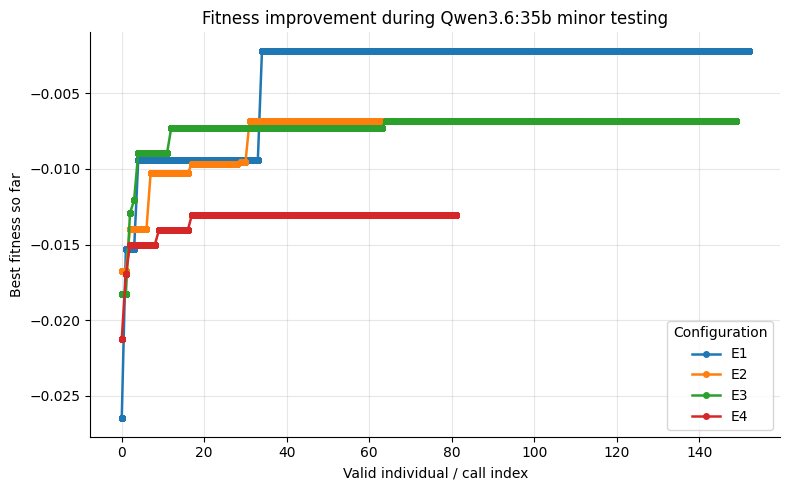

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))

for exp_name, sub in qwen_trace.groupby("experiment"):
    sub = sub.sort_values("call_idx")

    ax.plot(
        sub["call_idx"],
        sub["best_so_far"],
        marker="o",
        linewidth=1.8,
        markersize=4,
        label=exp_name
    )

ax.set_xlabel("Valid individual / call index")
ax.set_ylabel("Best fitness so far")
ax.set_title("Fitness improvement during Qwen3.6:35b minor testing")
ax.grid(alpha=0.3)
ax.legend(title="Configuration")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

Statistical Testing

In [17]:
summary_fid_k_mse = pd.read_csv("generalizability_mse_by_fid_k.csv")

summary_fid_k_mse

,experiment,test_set,fid,k,mean_mse,median_mse,std_mse,min_mse,max_mse,n_evaluations,n_algorithms
0,E1,new_fid_new_iid,9,2,0.037903,0.037903,NaN,0.037903,0.037903,1,1
1,E1,new_fid_new_iid,9,3,0.020727,0.020727,NaN,0.020727,0.020727,1,1
2,E1,new_fid_new_iid,9,5,0.015015,0.015015,NaN,0.015015,0.015015,1,1
3,E1,new_fid_new_iid,9,10,0.006237,0.006237,NaN,0.006237,0.006237,1,1
4,E1,new_fid_new_iid,10,2,0.051849,0.051849,NaN,0.051849,0.051849,1,1
...,...,...,...,...,...,...,...,...,...,...,...
283,E6,same_fid_new_iid,7,10,0.011368,0.011368,NaN,0.011368,0.011368,1,1
284,E6,same_fid_new_iid,8,2,0.110611,0.110611,NaN,0.110611,0.110611,1,1
285,E6,same_fid_new_iid,8,3,0.076698,0.076698,NaN,0.076698,0.076698,1,1
286,E6,same_fid_new_iid,8,5,0.020511,0.020511,NaN,0.020511,0.020511,1,1


In [18]:
from scipy.stats import wilcoxon
EXPERIMENT_LOGS = {
    "E1" : sorted(glob.glob(str(results_path / "without_domain_knowledge/*/log.jsonl"))),
    "E2" : sorted(glob.glob(str(results_path /"domain_knowledge/*/log.jsonl"))),
    "E3" : sorted(glob.glob(str(results_path /"mutation_5_runs_elitism_on/*/log.jsonl"))),
    "E4" : sorted(glob.glob(str(results_path /"warm_start_5_runs/*/log.jsonl"))),
    "E5" : sorted(glob.glob(str(results_path /"5_runs_mutation_prompts_WITH_DOMAIN_KNOWLEDGE/*/log.jsonl"))),
    "E6" : sorted(glob.glob(str(results_path /"5_runs_warm_start_WITH_DOMAIN_KNOWLEDGE/*/log.jsonl"))),
    }

DOMAIN_KNOWLEDGE_GROUPS = {
    "without_domain": ["E1", "E3", "E4"],
    "with_domain":    ["E2", "E5", "E6"],
}

# Paired Wilcoxon signed-rank test comparing without_domain vs with_domain
# MSE, paired by (fid, k).
def wilcoxon_domain_knowledge(summary_fid_k_mse, groups, test_set):
    without_exps = groups["without_domain"]
    with_exps    = groups["with_domain"]

    sub_without = summary_fid_k_mse[
        (summary_fid_k_mse["experiment"].isin(without_exps)) &
        (summary_fid_k_mse["test_set"] == test_set)
    ].groupby(["fid", "k"])["mean_mse"].median()

    sub_with = summary_fid_k_mse[
        (summary_fid_k_mse["experiment"].isin(with_exps)) &
        (summary_fid_k_mse["test_set"] == test_set)
    ].groupby(["fid", "k"])["mean_mse"].median()

    paired = pd.concat([sub_without, sub_with], axis=1, keys=["without", "with"]).dropna()

    if len(paired) < 1:
        print(f"{test_set}: no paired (fid, k) data available")
        return None

    diffs = paired["without"] - paired["with"]
    if (diffs == 0).all():
        print(f"{test_set}: all differences are zero, Wilcoxon undefined")
        return None

    try:
        stat, pval = wilcoxon(paired["without"], paired["with"], alternative="two-sided")
    except ValueError as e:
        print(f"{test_set}: Wilcoxon failed — {e}")
        return None

    median_diff = diffs.median()
    direction = "domain knowledge helps (lower MSE)" if median_diff > 0 else "domain knowledge hurts (higher MSE)" if median_diff < 0 else "no difference"

    result = {
        "test_set":     test_set,
        "n_pairs":      len(paired),
        "statistic":    stat,
        "p_value":      pval,
        "significant":  pval < 0.05,
        "median_diff":  median_diff,
        "direction":    direction,
    }

    print(f"\n── {test_set} ──")
    print(f"  n pairs: {len(paired)}")
    print(f"  Wilcoxon statistic: {stat:.4f}")
    print(f"  p-value: {pval:.4f} {'(significant)' if pval < 0.05 else '(not significant)'}")
    print(f"  median(without − with): {median_diff:+.6f} → {direction}")

    return result


wilcoxon_results = []
for test_set_name in summary_fid_k_mse["test_set"].unique():
    res = wilcoxon_domain_knowledge(summary_fid_k_mse, DOMAIN_KNOWLEDGE_GROUPS, test_set_name)
    if res is not None:
        wilcoxon_results.append(res)

wilcoxon_df = pd.DataFrame(wilcoxon_results)
print("\n── Summary ──")
print(wilcoxon_df.to_string(index=False))


── new_fid_new_iid ──
  n pairs: 8
  Wilcoxon statistic: 10.0000
  p-value: 0.3125 (not significant)
  median(without − with): +0.000840 → domain knowledge helps (lower MSE)

── new_fid_same_iid ──
  n pairs: 8
  Wilcoxon statistic: 9.0000
  p-value: 0.2500 (not significant)
  median(without − with): -0.000705 → domain knowledge hurts (higher MSE)

── same_fid_new_iid ──
  n pairs: 32
  Wilcoxon statistic: 116.0000
  p-value: 0.0047 (significant)
  median(without − with): -0.001912 → domain knowledge hurts (higher MSE)

── Summary ──
        test_set  n_pairs  statistic  p_value  significant  median_diff                           direction
 new_fid_new_iid        8       10.0  0.31250        False     0.000840  domain knowledge helps (lower MSE)
new_fid_same_iid        8        9.0  0.25000        False    -0.000705 domain knowledge hurts (higher MSE)
same_fid_new_iid       32      116.0  0.00471         True    -0.001912 domain knowledge hurts (higher MSE)


In [19]:
from scipy.stats import wilcoxon, mannwhitneyu

DOMAIN_KNOWLEDGE_GROUPS = {
    "without_domain": ["E1", "E3", "E4"],
    "with_domain":    ["E2", "E5", "E6"],
}

# collect ALL valid fitness values per experiment (not just top-N) 
FAILURE_THRESHOLD = -1e6  

def extract_all_fitness(log_paths, failure_threshold=FAILURE_THRESHOLD):
    fitness_vals = []
    for path in log_paths:
        with jsonlines.open(path) as reader:
            for obj in reader:
                items = obj if isinstance(obj, list) else [obj]
                for ind in items:
                    fitness = float(ind.get("fitness", np.nan))
                    code    = ind.get("code", "")
                    if code and np.isfinite(fitness) and fitness > failure_threshold:
                        fitness_vals.append(fitness)
    return np.array(fitness_vals)

exp_fitness = {
    exp_name: extract_all_fitness(log_paths)
    for exp_name, log_paths in EXPERIMENT_LOGS.items()
}

for exp_name, vals in exp_fitness.items():
    print(f"{exp_name}: n={len(vals)}, mean={vals.mean():.4f}, median={np.median(vals):.4f}, "
          f"min={vals.min():.4f}, max={vals.max():.4f}")

# ── pool fitness across experiments within each domain-knowledge group ────
without_domain_fitness = np.concatenate([exp_fitness[e] for e in DOMAIN_KNOWLEDGE_GROUPS["without_domain"]])
with_domain_fitness    = np.concatenate([exp_fitness[e] for e in DOMAIN_KNOWLEDGE_GROUPS["with_domain"]])

print(f"\nwithout_domain: n={len(without_domain_fitness)}, median={np.median(without_domain_fitness):.4f}")
print(f"with_domain:    n={len(with_domain_fitness)}, median={np.median(with_domain_fitness):.4f}")

E1: n=886, mean=-0.0117, median=-0.0108, min=-0.0789, max=-0.0045
E2: n=773, mean=-0.0128, median=-0.0123, min=-0.0552, max=-0.0044
E3: n=868, mean=-0.0110, median=-0.0106, min=-0.0427, max=-0.0045
E4: n=899, mean=-0.0108, median=-0.0092, min=-0.2564, max=-0.0026
E5: n=732, mean=-0.0120, median=-0.0113, min=-0.0375, max=-0.0029
E6: n=699, mean=-0.1213, median=-0.1775, min=-0.2041, max=-0.0057

without_domain: n=2653, median=-0.0100
with_domain:    n=2204, median=-0.0130


In [20]:
stat, pval = mannwhitneyu(without_domain_fitness, with_domain_fitness, alternative="two-sided")

print(f"\n── Mann-Whitney U: without_domain vs with_domain (all individuals) ──")
print(f"  n_without={len(without_domain_fitness)}, n_with={len(with_domain_fitness)}")
print(f"  U statistic: {stat:.4f}")
print(f"  p-value: {pval:.6f} {'(significant)' if pval < 0.05 else '(not significant)'}")
print(f"  median without: {np.median(without_domain_fitness):.4f}")
print(f"  median with:    {np.median(with_domain_fitness):.4f}")


── Mann-Whitney U: without_domain vs with_domain (all individuals) ──
  n_without=2653, n_with=2204
  U statistic: 4695667.0000
  p-value: 0.000000 (significant)
  median without: -0.0100
  median with:    -0.0130


In [21]:
def extract_fitness_by_run(log_paths, failure_threshold=FAILURE_THRESHOLD):
    """One row per run, with best fitness in that run."""
    run_best = []
    for run_idx, path in enumerate(log_paths):
        vals = []
        with jsonlines.open(path) as reader:
            for obj in reader:
                items = obj if isinstance(obj, list) else [obj]
                for ind in items:
                    f = ind.get("fitness", np.nan)
                    code = ind.get("code", "")
                    if code and f is not None and np.isfinite(float(f)) and float(f) > failure_threshold:
                        vals.append(float(f))
        if vals:
            run_best.append(max(vals))  # or np.mean(vals), depending on what you want to compare
    return np.array(run_best)

exp_run_best = {
    exp_name: extract_fitness_by_run(log_paths)
    for exp_name, log_paths in EXPERIMENT_LOGS.items()
}

for exp_name, vals in exp_run_best.items():
    print(f"{exp_name}: n_runs={len(vals)}, median best fitness={np.median(vals):.4f}")

without_domain_runs = np.concatenate([exp_run_best[e] for e in DOMAIN_KNOWLEDGE_GROUPS["without_domain"]])
with_domain_runs    = np.concatenate([exp_run_best[e] for e in DOMAIN_KNOWLEDGE_GROUPS["with_domain"]])

print(f"\nn_without_runs={len(without_domain_runs)}, n_with_runs={len(with_domain_runs)}")

stat, pval = mannwhitneyu(without_domain_runs, with_domain_runs, alternative="two-sided")
print(f"Mann-Whitney U (run-level): stat={stat:.4f}, p={pval:.4f}")


E1: n_runs=5, median best fitness=-0.0065
E2: n_runs=5, median best fitness=-0.0088
E3: n_runs=5, median best fitness=-0.0077
E4: n_runs=5, median best fitness=-0.0068
E5: n_runs=5, median best fitness=-0.0088
E6: n_runs=5, median best fitness=-0.1624

n_without_runs=15, n_with_runs=15
Mann-Whitney U (run-level): stat=170.0000, p=0.0181


In [22]:
# pairs: list of (without_exp, with_exp) tuples, e.g. [("E1","E2"), ("E3","E5"), ("E4","E6")]
# Pairs run i of without_exp with run i of with_exp.
def paired_wilcoxon_domain_knowledge(exp_run_best, pairs):
    all_without = []
    all_with = []

    for without_exp, with_exp in pairs:
        a = exp_run_best[without_exp]
        b = exp_run_best[with_exp]
        n = min(len(a), len(b))
        if len(a) != len(b):
            print(f"Warning: {without_exp} has {len(a)} runs, {with_exp} has {len(b)} runs. Truncating to {n}.")
        all_without.extend(a[:n])
        all_with.extend(b[:n])

    all_without = np.array(all_without)
    all_with = np.array(all_with)

    diffs = all_without - all_with
    if (diffs == 0).all():
        print("All differences are zero, Wilcoxon undefined")
        return None

    stat, pval = wilcoxon(all_without, all_with, alternative="two-sided")

    print(f"n pairs: {len(all_without)}")
    print(f"Wilcoxon statistic: {stat:.4f}")
    print(f"p-value: {pval:.4f} {'(significant)' if pval < 0.05 else '(not significant)'}")
    print(f"median(without − with): {np.median(diffs):+.6f}")

    return stat, pval

pairs = [("E1", "E2"), ("E3", "E5"), ("E4", "E6")]
paired_wilcoxon_domain_knowledge(exp_run_best, pairs)

n pairs: 15
Wilcoxon statistic: 18.0000
p-value: 0.0151 (significant)
median(without − with): +0.002463


(np.float64(18.0), np.float64(0.01507568359375))

In [23]:
from scipy.stats import wilcoxon

# Returns a list of arrays, one per run (in file order)
def extract_fitness_sequence_per_run(log_paths, failure_threshold=FAILURE_THRESHOLD):

    run_sequences = []
    for path in log_paths:
        vals = []
        with jsonlines.open(path) as reader:
            for obj in reader:
                items = obj if isinstance(obj, list) else [obj]
                for ind in items:
                    f = ind.get("fitness", np.nan)
                    code = ind.get("code", "")
                    if code and f is not None and np.isfinite(float(f)) and float(f) > failure_threshold:
                        vals.append(float(f))
        run_sequences.append(np.array(vals))
    return run_sequences

# Paired Wilcoxon signed-rank test comparing without_domain vs with_domain
def paired_wilcoxon_pointwise(exp_logs, pairs, failure_threshold=FAILURE_THRESHOLD):
    all_without = []
    all_with = []

    for without_exp, with_exp in pairs:
        without_runs = extract_fitness_sequence_per_run(EXPERIMENT_LOGS[without_exp], failure_threshold)
        with_runs    = extract_fitness_sequence_per_run(EXPERIMENT_LOGS[with_exp], failure_threshold)

        n_runs = min(len(without_runs), len(with_runs))
        if len(without_runs) != len(with_runs):
            print(f"Warning: {without_exp} has {len(without_runs)} runs, {with_exp} has {len(with_runs)} runs. Using {n_runs}.")

        for i in range(n_runs):
            a = without_runs[i]
            b = with_runs[i]
            n_points = min(len(a), len(b))
            if len(a) != len(b):
                print(f"  Run {i}: {without_exp} has {len(a)} points, {with_exp} has {len(b)} points. Truncating to {n_points}.")
            all_without.extend(a[:n_points])
            all_with.extend(b[:n_points])

    return np.array(all_without), np.array(all_with)


pairs = [("E1", "E2"), ("E3", "E5"), ("E4", "E6")]
without_pts, with_pts = paired_wilcoxon_pointwise(EXPERIMENT_LOGS, pairs)

print(f"\nTotal paired points: {len(without_pts)}")

diffs = without_pts - with_pts
if (diffs == 0).all():
    print("All differences are zero, Wilcoxon undefined")
else:
    stat, pval = wilcoxon(without_pts, with_pts, alternative="two-sided")
    print(f"Wilcoxon statistic: {stat:.4f}")
    print(f"p-value: {pval:.6f} {'(significant)' if pval < 0.05 else '(not significant)'}")
    print(f"median(without − with): {np.median(diffs):+.6f}")

  Run 0: E1 has 168 points, E2 has 102 points. Truncating to 102.
  Run 1: E1 has 194 points, E2 has 189 points. Truncating to 189.
  Run 2: E1 has 183 points, E2 has 190 points. Truncating to 183.
  Run 3: E1 has 157 points, E2 has 184 points. Truncating to 157.
  Run 4: E1 has 184 points, E2 has 108 points. Truncating to 108.
  Run 0: E3 has 161 points, E5 has 151 points. Truncating to 151.
  Run 1: E3 has 187 points, E5 has 78 points. Truncating to 78.
  Run 2: E3 has 165 points, E5 has 163 points. Truncating to 163.
  Run 3: E3 has 185 points, E5 has 174 points. Truncating to 174.
  Run 4: E3 has 170 points, E5 has 166 points. Truncating to 166.
  Run 0: E4 has 183 points, E6 has 176 points. Truncating to 176.
  Run 1: E4 has 189 points, E6 has 111 points. Truncating to 111.
  Run 2: E4 has 160 points, E6 has 59 points. Truncating to 59.
  Run 3: E4 has 183 points, E6 has 179 points. Truncating to 179.
  Run 4: E4 has 184 points, E6 has 174 points. Truncating to 174.

Total paired 

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, rankdata

# Build paired run-level dataframe
pairs = [("E1", "E2"), ("E3", "E5"), ("E4", "E6")]

rows = []

for without_exp, with_exp in pairs:
    without_vals = np.asarray(exp_run_best[without_exp], dtype=float)
    with_vals = np.asarray(exp_run_best[with_exp], dtype=float)

    n = min(len(without_vals), len(with_vals))

    for i in range(n):
        rows.append({
            "comparison": f"{without_exp} vs {with_exp}",
            "run": i + 1,
            "without": without_vals[i],
            "with": with_vals[i],
            "diff_without_minus_with": without_vals[i] - with_vals[i],
        })

paired_df = pd.DataFrame(rows)

# statistics

diffs = paired_df["diff_without_minus_with"].to_numpy()
without = paired_df["without"].to_numpy()
with_domain = paired_df["with"].to_numpy()

stat, pval = wilcoxon(without, with_domain, alternative="two-sided")

median_without = np.median(without)
median_with = np.median(with_domain)
median_diff = np.median(diffs)

# bootstrap CI for the median paired difference
rng = np.random.default_rng(42)
B = 10_000
boot_medians = np.array([
    np.median(rng.choice(diffs, size=len(diffs), replace=True))
    for _ in range(B)
])
ci_low, ci_high = np.percentile(boot_medians, [2.5, 97.5])

# rank-biserial correlation for paired Wilcoxon
nonzero_diffs = diffs[diffs != 0]
ranks = rankdata(np.abs(nonzero_diffs))
w_plus = np.sum(ranks[nonzero_diffs > 0])
w_minus = np.sum(ranks[nonzero_diffs < 0])
rank_biserial = (w_plus - w_minus) / np.sum(ranks)

n_with_better = np.sum(diffs < 0)
n_without_better = np.sum(diffs > 0)
n_equal = np.sum(diffs == 0)

summary = pd.DataFrame([{
    "n_pairs": len(diffs),
    "median_without": median_without,
    "median_with": median_with,
    "median_without_minus_with": median_diff,
    "95% CI lower": ci_low,
    "95% CI upper": ci_high,
    "wilcoxon_statistic": stat,
    "p_value": pval,
    "rank_biserial_r": rank_biserial,
    "without_better": n_without_better,
    "with_better": n_with_better,
    "equal": n_equal,
}])

print(summary.round(6))

   n_pairs  median_without  median_with  median_without_minus_with  \
0       15       -0.007345    -0.008827                   0.002463   

   95% CI lower  95% CI upper  wilcoxon_statistic   p_value  rank_biserial_r  \
0     -0.000086      0.004325                18.0  0.015076              0.7   

   without_better  with_better  equal  
0              11            4      0  


In [25]:
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, rankdata

# build paired dataframe

pairs = [("E1", "E2"), ("E3", "E5"), ("E4", "E6")]

rows = []

for without_exp, with_exp in pairs:
    without_vals = np.asarray(exp_run_best[without_exp], dtype=float)
    with_vals = np.asarray(exp_run_best[with_exp], dtype=float)

    n = min(len(without_vals), len(with_vals))

    for i in range(n):
        rows.append({
            "comparison": f"{without_exp}--{with_exp}",
            "run": i + 1,
            "without": without_vals[i],
            "with": with_vals[i],
            "delta": without_vals[i] - with_vals[i],
        })

paired_df = pd.DataFrame(rows)

# median bootstrap CI for paired differences

def bootstrap_median_ci(values, n_boot=10_000, seed=42):
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)

    boot = np.array([
        np.median(rng.choice(values, size=len(values), replace=True))
        for _ in range(n_boot)
    ])

    return np.percentile(boot, [2.5, 97.5])


def rank_biserial_from_diffs(diffs):
    diffs = np.asarray(diffs, dtype=float)
    nonzero = diffs[diffs != 0]

    if len(nonzero) == 0:
        return np.nan

    ranks = rankdata(np.abs(nonzero))
    w_plus = np.sum(ranks[nonzero > 0])
    w_minus = np.sum(ranks[nonzero < 0])

    return (w_plus - w_minus) / np.sum(ranks)


# overall Wilcoxon table

diffs = paired_df["delta"].to_numpy()
without = paired_df["without"].to_numpy()
with_domain = paired_df["with"].to_numpy()

stat, pval = wilcoxon(without, with_domain, alternative="two-sided")

ci_low, ci_high = bootstrap_median_ci(diffs)
r_rb = rank_biserial_from_diffs(diffs)

overall_table = pd.DataFrame([{
    "Comparison": "All matched pairs",
    "n pairs": len(diffs),
    "Median without": np.median(without),
    "Median with": np.median(with_domain),
    "Median Δ": np.median(diffs),
    "95% CI for median Δ": f"[{ci_low:+.4f}, {ci_high:+.4f}]",
    "Wilcoxon W": stat,
    "p-value": pval,
    "Rank-biserial r": r_rb,
}])

# breakdown by configuration pair
breakdown_rows = []

for comp, sub in paired_df.groupby("comparison"):
    d = sub["delta"].to_numpy()
    ci_l, ci_u = bootstrap_median_ci(d)

    without_better = np.sum(d > 0)
    with_better = np.sum(d < 0)
    equal = np.sum(d == 0)

    breakdown_rows.append({
        "Pair": comp,
        "n": len(d),
        "Median without": np.median(sub["without"]),
        "Median with": np.median(sub["with"]),
        "Median Δ": np.median(d),
        "95% CI for median Δ": f"[{ci_l:+.4f}, {ci_u:+.4f}]",
        "Without better": without_better,
        "With better": with_better,
        "Equal": equal,
    })

breakdown_table = pd.DataFrame(breakdown_rows)

def format_table(df):
    formatted = df.copy()

    for col in formatted.columns:
        if col in [
            "Median without",
            "Median with",
            "Median Δ",
            "p-value",
            "Rank-biserial r",
        ]:
            formatted[col] = formatted[col].map(lambda x: f"{x:.4f}")

        if col == "Wilcoxon W":
            formatted[col] = formatted[col].map(lambda x: f"{x:.1f}")

    return formatted

overall_table_fmt = format_table(overall_table)
breakdown_table_fmt = format_table(breakdown_table)

print("\nOverall Wilcoxon table:")
print(overall_table_fmt.to_string(index=False))

print("\nBreakdown table:")
print(breakdown_table_fmt.to_string(index=False))



Overall Wilcoxon table:
       Comparison  n pairs Median without Median with Median Δ 95% CI for median Δ Wilcoxon W p-value Rank-biserial r
All matched pairs       15        -0.0073     -0.0088   0.0025  [-0.0001, +0.0043]       18.0  0.0151          0.7000

Breakdown table:
  Pair  n Median without Median with Median Δ 95% CI for median Δ  Without better  With better  Equal
E1--E2  5        -0.0065     -0.0088   0.0025  [-0.0012, +0.0041]               3            2      0
E3--E5  5        -0.0077     -0.0088   0.0012  [-0.0072, +0.0043]               4            1      0
E4--E6  5        -0.0068     -0.1624   0.1598  [-0.0010, +0.1690]               4            1      0


In [26]:
import numpy as np
import pandas as pd
from scipy.stats import rankdata, wilcoxon

# build df paired

pairs = [("E1", "E2"), ("E3", "E5"), ("E4", "E6")]

rows = []

for without_exp, with_exp in pairs:
    without_vals = np.asarray(exp_run_best[without_exp], dtype=float)
    with_vals = np.asarray(exp_run_best[with_exp], dtype=float)

    n = min(len(without_vals), len(with_vals))

    for i in range(n):
        rows.append({
            "pair": f"{without_exp}--{with_exp}",
            "run": i + 1,
            "without": without_vals[i],
            "with": with_vals[i],
            "delta": without_vals[i] - with_vals[i],
        })

paired_df = pd.DataFrame(rows)

# wilcoxon signed-rank statistics

diffs = paired_df["delta"].to_numpy()

# remove zero differences for ranking
nonzero_diffs = diffs[diffs != 0]
ranks = rankdata(np.abs(nonzero_diffs), method="average")

positive_ranks = ranks[nonzero_diffs > 0]
negative_ranks = ranks[nonzero_diffs < 0]

n_positive = len(positive_ranks)
n_negative = len(negative_ranks)
n_ties = int(np.sum(diffs == 0))
n_total = len(diffs)

sum_positive = np.sum(positive_ranks)
sum_negative = np.sum(negative_ranks)

mean_positive = np.mean(positive_ranks) if n_positive > 0 else 0
mean_negative = np.mean(negative_ranks) if n_negative > 0 else 0

# wilcoxon test
stat, pval = wilcoxon(
    paired_df["without"],
    paired_df["with"],
    alternative="two-sided"
)

# rank-biserial correlation
rank_biserial = (sum_positive - sum_negative) / (sum_positive + sum_negative)

median_delta = np.median(diffs)


wilcoxon_table = pd.DataFrame([
    {
        "Difference": r"$f_{\mathrm{without}} - f_{\mathrm{with}}$",
        "Direction": "Negative ranks",
        "$N$": n_negative,
        "Mean rank": mean_negative,
        "Sum of ranks": sum_negative,
        "Median $\\Delta$": "",
        "$W$": "",
        "$p$": "",
        "$r_{rb}$": "",
    },
    {
        "Difference": r"$f_{\mathrm{without}} - f_{\mathrm{with}}$",
        "Direction": "Positive ranks",
        "$N$": n_positive,
        "Mean rank": mean_positive,
        "Sum of ranks": sum_positive,
        "Median $\\Delta$": "",
        "$W$": "",
        "$p$": "",
        "$r_{rb}$": "",
    },
    {
        "Difference": r"$f_{\mathrm{without}} - f_{\mathrm{with}}$",
        "Direction": "Ties",
        "$N$": n_ties,
        "Mean rank": "",
        "Sum of ranks": "",
        "Median $\\Delta$": "",
        "$W$": "",
        "$p$": "",
        "$r_{rb}$": "",
    },
    {
        "Difference": r"$f_{\mathrm{without}} - f_{\mathrm{with}}$",
        "Direction": "Total / test statistic",
        "$N$": n_total,
        "Mean rank": "",
        "Sum of ranks": "",
        "Median $\\Delta$": f"{median_delta:+.4f}",
        "$W$": f"{stat:.1f}",
        "$p$": f"{pval:.4f}",
        "$r_{rb}$": f"{rank_biserial:.4f}",
    },
])

# format numeric columns
for col in ["Mean rank", "Sum of ranks"]:
    wilcoxon_table[col] = wilcoxon_table[col].apply(
        lambda x: f"{x:.2f}" if isinstance(x, (int, float, np.integer, np.floating)) else x
    )
# format numeric columns
for col in ["Mean rank", "Sum of ranks"]:
    wilcoxon_table[col] = wilcoxon_table[col].apply(
        lambda x: f"{x:.2f}"
        if isinstance(x, (int, float, np.integer, np.floating))
        else x
    )

print("\nWilcoxon signed-rank test:")
print(wilcoxon_table.to_string(index=False))



Wilcoxon signed-rank test:
                                Difference              Direction  $N$ Mean rank Sum of ranks Median $\Delta$  $W$    $p$ $r_{rb}$
$f_{\mathrm{without}} - f_{\mathrm{with}}$         Negative ranks    4      4.50        18.00                                     
$f_{\mathrm{without}} - f_{\mathrm{with}}$         Positive ranks   11      9.27       102.00                                     
$f_{\mathrm{without}} - f_{\mathrm{with}}$                   Ties    0                                                            
$f_{\mathrm{without}} - f_{\mathrm{with}}$ Total / test statistic   15                                +0.0025 18.0 0.0151   0.7000


In [27]:

table_df = pd.DataFrame([{
    "Comparison": "Without vs. with domain knowledge",
    "n pairs": len(diffs),
    "Median without": median_without,
    "Median with": median_with,
    "Median Δ": median_diff,
    "95% CI for Δ": f"[{ci_low:+.4f}, {ci_high:+.4f}]",
    "Wilcoxon W": stat,
    "p-value": pval,
    "Rank-biserial r": rank_biserial,
}])

table_df_rounded = table_df.copy()

for col in ["Median without", "Median with", "Median Δ", "p-value", "Rank-biserial r"]:
    table_df_rounded[col] = table_df_rounded[col].map(lambda x: f"{x:.4f}")

table_df_rounded["Wilcoxon W"] = table_df_rounded["Wilcoxon W"].map(lambda x: f"{x:.1f}")

print(table_df_rounded.to_string(index=False))

                       Comparison  n pairs Median without Median with Median Δ       95% CI for Δ Wilcoxon W p-value Rank-biserial r
Without vs. with domain knowledge       15        -0.0073     -0.0088   0.0025 [-0.0001, +0.0043]       18.0  0.0151          0.7000


## Cliff's Delta

In [28]:
# Reload perf_df 
FAILURE_THRESHOLD = -1e6
import jsonlines, json, glob, os
EXPERIMENTS_IOH = {
    "E1: No domain knowledge":              sorted(glob.glob(str(results_path / "without_domain_knowledge/*/log.jsonl"))),
    "E2: Domain knowledge":                 sorted(glob.glob(str(results_path / "domain_knowledge/*/log.jsonl"))),
    "E3: Mutation w/o Elitism":               sorted(glob.glob(str(results_path / "mutation_5_runs_elitism_off_16/*/log.jsonl"))),
    "E4: Warm Start w/o Elitism":             sorted(glob.glob(str(results_path / "warm_start_5_runs_elitism_off_16_child/*/log.jsonl"))),
    "E5: Mutation + Elitism":             sorted(glob.glob(str(results_path / "mutation_5_runs_elitism_on/*/log.jsonl"))),
    "E6: Warm Start + Elitism":           sorted(glob.glob(str(results_path / "warm_start_5_runs/*/log.jsonl"))),
}

def load_experiment_performance(run_paths: list[str], label: str) -> pd.DataFrame:
    """
    Extract per-algorithm, per-problem performance from log.jsonl files.
    Returns a DataFrame with columns:
        experiment, run, call_idx, name, fitness, fid, k, auc_imp, baseline_mse
    """
    rows = []
    for run_idx, path in enumerate(run_paths):
        try:
            with jsonlines.open(path) as reader:
                for call_idx, obj in enumerate(reader, start=1):
                    if not isinstance(obj, dict):
                        continue

                    fitness      = obj.get("fitness", np.nan)
                    name         = obj.get("name", "")
                    metadata     = obj.get("metadata", {})
                    perf_data    = metadata.get("performance_data", [])

                    if not perf_data:
                        # entry has no performance data (e.g. failed run)
                        rows.append({
                            "experiment":   label,
                            "run":          run_idx,
                            "call_idx":     call_idx,
                            "name":         name,
                            "fitness":      fitness,
                            "fid":          np.nan,
                            "k":            np.nan,
                            "problem_name": np.nan,
                            "auc_imp":      np.nan,
                            "baseline_mse": np.nan,
                        })
                    else:
                        for prob in perf_data:
                            rows.append({
                                "experiment":   label,
                                "run":          run_idx,
                                "call_idx":     call_idx,
                                "name":         name,
                                "fitness":      fitness,
                                "fid":          prob.get("fid"),
                                "k":            prob.get("k"),
                                "problem_name": prob.get("problem_name", ""),
                                "auc_imp":      prob.get("auc_imp", np.nan),
                                "baseline_mse": prob.get("baseline_mse", np.nan),
                            })

        except Exception as e:
            print(f"  Failed to load {path}: {type(e).__name__}: {e}")

    df = pd.DataFrame(rows)
    print(f"{label}: {len(run_paths)} runs, {df['call_idx'].nunique()} unique calls, "
          f"{len(df)} total problem-level records")
    return df


# load KMeans++ baseline 
def load_kmeans_baseline(path: str) -> pd.DataFrame:
    """
    Load KMeans++ baseline CSV.
    Expected columns: fid, k, auc_imp (or similar).
    Prints columns so you can verify mapping.
    """
    df = pd.read_csv(path)
    print(f"KMeans++ CSV columns: {df.columns.tolist()}")
    print(df.head(3))
    return df


all_perf = {}
for exp_label, paths in EXPERIMENTS_IOH.items():
    all_perf[exp_label] = load_experiment_performance(paths, exp_label)

BASELINE_PATHS = sorted(glob.glob(str(BASE_DIR / "KMeansCompare.csv")))
baseline_path = BASELINE_PATHS[0]
kmeans_df = load_kmeans_baseline(baseline_path)

# concatenated df for convenience
perf_df = pd.concat(all_perf.values(), ignore_index=True)
print(f"\nTotal records: {len(perf_df)}")
print(perf_df["experiment"].value_counts())

print(f"Total records: {len(perf_df)}")
print(perf_df["experiment"].value_counts())

E1: No domain knowledge: 5 runs, 200 unique calls, 29659 total problem-level records
E2: Domain knowledge: 5 runs, 200 unique calls, 26358 total problem-level records
E3: Mutation w/o Elitism: 5 runs, 200 unique calls, 27140 total problem-level records
E4: Warm Start w/o Elitism: 5 runs, 200 unique calls, 27567 total problem-level records
E5: Mutation + Elitism: 5 runs, 200 unique calls, 29582 total problem-level records
E6: Warm Start + Elitism: 5 runs, 200 unique calls, 29582 total problem-level records
KMeans++ CSV columns: ['dataset', 'k', 'mse']
   dataset  k       mse
0        1  2  0.044068
1        1  3  0.029825
2        1  5  0.014901

Total records: 169888
experiment
E1: No domain knowledge       29659
E6: Warm Start + Elitism      29582
E5: Mutation + Elitism        29582
E4: Warm Start w/o Elitism    27567
E3: Mutation w/o Elitism      27140
E2: Domain knowledge          26358
Name: count, dtype: int64
Total records: 169888
experiment
E1: No domain knowledge       29659
E6

In [29]:
import numpy as np

def cliffs_delta(a, b) -> float:
    """Exact Cliff's delta in O(n log n), no pairwise matrix. Positive = a tends to be larger than b."""
    a = np.asarray(a, float)
    b = np.sort(np.asarray(b, float))
    a_gt_b = np.searchsorted(b, a, side="left").sum()
    a_lt_b = (len(b) - np.searchsorted(b, a, side="right")).sum()
    return float((a_gt_b - a_lt_b) / (len(a) * len(b)))

def cliffs_delta_magnitude(d: float) -> str:
    d = abs(d)
    return "negligible" if d < 0.147 else "small" if d < 0.330 else "medium" if d < 0.474 else "large"

# quick check against the brute-force definition on small data
rng = np.random.default_rng(0)
x, y = rng.normal(size=50), rng.normal(0.3, 1, size=60)
brute = np.sign(x[:, None] - y[None, :]).mean()
assert abs(cliffs_delta(x, y) - brute) < 1e-12

In [30]:
import numpy as np, pandas as pd

def cand_values(perf_df, exp, how, fail=-5e8):
    d = perf_df[perf_df["experiment"] == exp].copy()
    d["auc_clean"] = d["auc_imp"].where(d["auc_imp"] > fail)       # -1e9 -> NaN
    g = d.groupby(["run", "call_idx"])
    if how == "mean_incl_failures":                                 # what you have now
        return g["auc_imp"].mean().dropna().to_numpy()
    if how == "mean_valid_problems":                                # failed problems ignored
        return g["auc_clean"].mean().dropna().to_numpy()
    if how == "fully_valid_only":                                   # drop candidates with any failure
        m = g["auc_clean"].agg(lambda s: s.mean() if s.notna().all() else np.nan)
        return m.dropna().to_numpy()
    if how == "fitness_col":                                        # the logged fitness
        f = g["fitness"].first()
        return f[np.isfinite(f) & (f > fail)].to_numpy()

labels = list(EXPERIMENTS_IOH.keys())
for how in ["mean_incl_failures", "mean_valid_problems", "fully_valid_only"]:
    vals = {e: cand_values(perf_df, e, how) for e in labels}
    print(f"\n{how}:  n =", {e.split(':')[0]: len(v) for e, v in vals.items()})
    M = pd.DataFrame(
        [[cliffs_delta(vals[a], vals[b]) if a != b else np.nan for b in labels] for a in labels],
        index=[e.split(":")[0] for e in labels], columns=[e.split(":")[0] for e in labels])
    print(M.round(2).to_string())


mean_incl_failures:  n = {'E1': 900, 'E2': 793, 'E3': 819, 'E4': 796, 'E5': 888, 'E6': 911}
      E1    E2    E3    E4    E5    E6
E1   NaN  0.37  0.28  0.50 -0.00 -0.35
E2 -0.37   NaN -0.07  0.18 -0.43 -0.70
E3 -0.28  0.07   NaN  0.24 -0.33 -0.57
E4 -0.50 -0.18 -0.24   NaN -0.57 -0.74
E5  0.00  0.43  0.33  0.57   NaN -0.42
E6  0.35  0.70  0.57  0.74  0.42   NaN

mean_valid_problems:  n = {'E1': 900, 'E2': 793, 'E3': 819, 'E4': 796, 'E5': 888, 'E6': 911}
      E1    E2    E3    E4    E5    E6
E1   NaN  0.37  0.28  0.50 -0.00 -0.35
E2 -0.37   NaN -0.07  0.18 -0.43 -0.70
E3 -0.28  0.07   NaN  0.24 -0.33 -0.57
E4 -0.50 -0.18 -0.24   NaN -0.57 -0.74
E5  0.00  0.43  0.33  0.57   NaN -0.42
E6  0.35  0.70  0.57  0.74  0.42   NaN

fully_valid_only:  n = {'E1': 886, 'E2': 773, 'E3': 787, 'E4': 781, 'E5': 868, 'E6': 899}
      E1    E2    E3    E4    E5    E6
E1   NaN  0.38  0.28  0.51 -0.00 -0.35
E2 -0.38   NaN -0.08  0.18 -0.44 -0.70
E3 -0.28  0.08   NaN  0.25 -0.32 -0.57
E4 -0.51 -0.18 -0.25

{'E1': 886, 'E2': 773, 'E3': 787, 'E4': 781, 'E5': 868, 'E6': 899}


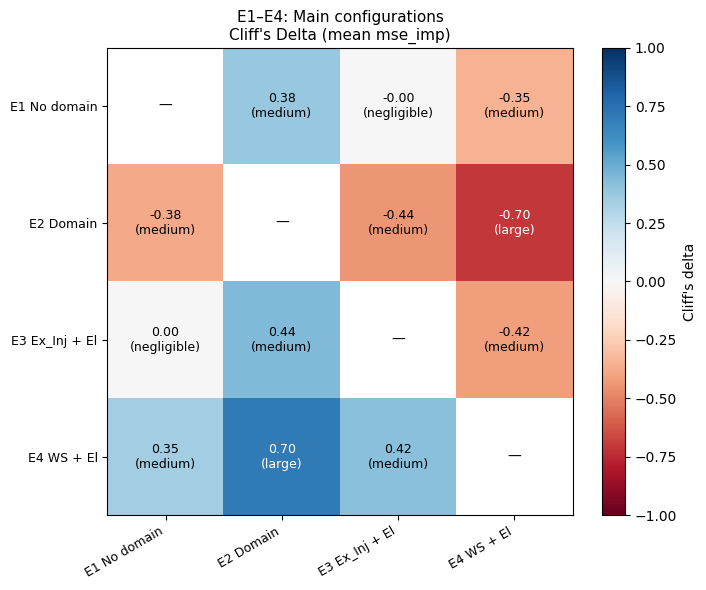

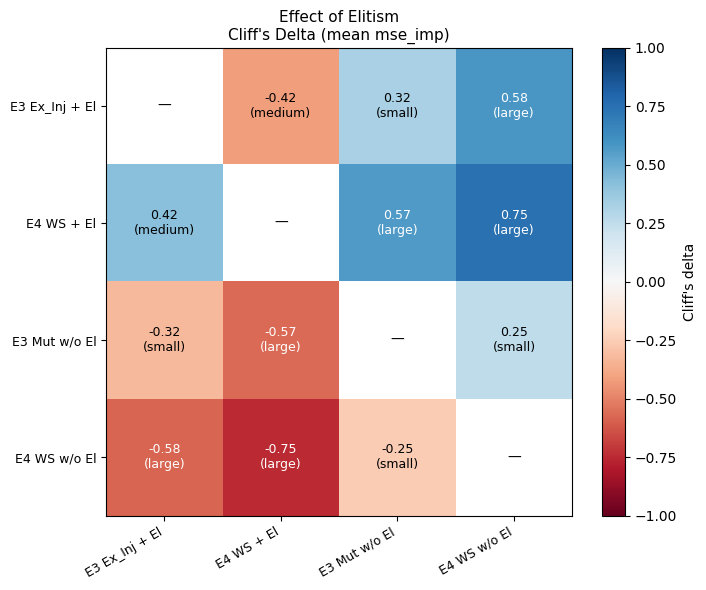

(          E5        E6        E3        E4
 E5       NaN -0.418942  0.323482  0.579860
 E6  0.418942       NaN  0.569331  0.748427
 E3 -0.323482 -0.569331       NaN  0.253490
 E4 -0.579860 -0.748427 -0.253490       NaN,
         E5      E6     E3     E4
 E5          medium  small  large
 E6  medium          large  large
 E3   small   large         small
 E4   large   large  small       )

In [31]:
labels = list(EXPERIMENTS_IOH.keys())
by_id = {l.split(":")[0].strip(): l for l in labels}

# one value per candidate, fully valid on all problems 
exp_values = {e: cand_values(perf_df, e, "fully_valid_only") for e in labels}
print({k.split(":")[0]: len(v) for k, v in exp_values.items()})

short_labels = {
    "E1": "E1 No domain", "E2": "E2 Domain",
    "E5": "E3 Ex_Inj + El", "E6": "E4 WS + El",     
    "E3": "E3 Mut w/o El", "E4": "E4 WS w/o El",
}

def plot_cliffs_heatmap(ids, title, metric_name="mean AUC_imp", save_as="Elitism_CliffsDelta.png"):
    n = len(ids)
    delta = pd.DataFrame(np.nan, index=ids, columns=ids)
    mag = pd.DataFrame("", index=ids, columns=ids)

    for a, b in combinations(ids, 2):
        d = cliffs_delta(exp_values[by_id[a]], exp_values[by_id[b]])
        delta.loc[a, b], delta.loc[b, a] = d, -d            # antisymmetric
        mag.loc[a, b] = mag.loc[b, a] = cliffs_delta_magnitude(d)

    fig, ax = plt.subplots(figsize=(max(6, n * 1.8), max(5, n * 1.5)))
    im = ax.imshow(delta.values.astype(float), cmap="RdBu", vmin=-1, vmax=1, aspect="auto")
    plt.colorbar(im, ax=ax, label="Cliff's delta")

    labels = [short_labels[i] for i in ids]
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=9)
    ax.set_yticklabels(labels, fontsize=9)

    for i, ra in enumerate(ids):
        for j, cb in enumerate(ids):
            val = delta.loc[ra, cb]
            if pd.isna(val):
                ax.text(j, i, "—", ha="center", va="center", fontsize=10)
            else:
                ax.text(j, i, f"{val:.2f}\n({mag.loc[ra, cb]})",
                        ha="center", va="center", fontsize=9,
                        color="white" if abs(val) > 0.5 else "black")

    ax.set_title(f"{title}\nCliff's Delta ({metric_name})", fontsize=11)
    plt.tight_layout()
    if save_as:
        plt.savefig(save_as, dpi=300, bbox_inches="tight")
    plt.show()
    return delta, mag

plot_cliffs_heatmap(["E1", "E2", "E5", "E6"], "E1–E4: Main configurations",
                    metric_name="mean mse_imp")
plot_cliffs_heatmap(["E5", "E6", "E3", "E4"], "Effect of Elitism",
                    metric_name="mean mse_imp")

In [32]:
import iohinspector
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from scipy.stats import mannwhitneyu

# align CMA-ES data

DATA_PATH = BASE_DIR / "Data"
dm = iohinspector.DataManager()
dm.add_folder(DATA_PATH)
dt = dm.overview.to_pandas()

# filter to fid 1-8 to match training 
dt = dt[dt["function_id"].between(1, 8)].copy()

# map dim → k (dim = 2*k for clustering problems)
# adjust this mapping if your dimension encoding differs
DIM_TO_K = {4: 2, 6: 3, 10: 5, 20: 10}
dt["k"] = dt["dimension"].map(DIM_TO_K)
dt = dt[dt["k"].notna()].copy()
dt["k"] = dt["k"].astype(int)
dt = dt.rename(columns={"function_id": "fid"})

# load KMeans++ baseline 
kmeans_df = pd.read_csv(str(BASE_DIR /"KMeansCompare.csv"))
kmeans_df = kmeans_df.rename(columns={"dataset": "fid", "mse": "baseline_mse"})
print("KMeans++ columns:", kmeans_df.columns.tolist())

# CMA-ES auc_imp relative to KMeans++ baseline
# auc_imp = best_y - baseline_mse (lower MSE is better, so negative = better)
cmaes_merged = dt.merge(
    kmeans_df[["fid", "k", "baseline_mse"]],
    on=["fid", "k"],
    how="inner"
)
cmaes_merged["auc_imp"] = cmaes_merged["best_y"] - cmaes_merged["baseline_mse"]
cmaes_merged["experiment"] = "CMA-ES"
cmaes_merged["name"] = "CMA-ES"
cmaes_merged["run"] = range(len(cmaes_merged))
cmaes_merged["call_idx"] = 1

print(f"\nCMA-ES records after alignment: {len(cmaes_merged)}")
print(cmaes_merged[["fid", "k", "best_y", "baseline_mse", "auc_imp"]].head(8))

# build unified comparison dataframe
# perf_df already has: experiment, run, call_idx, name, fid, k, auc_imp
# add KMeans++ as explicit entity (auc_imp = 0 by definition)
problems = perf_df[["fid", "k"]].drop_duplicates().sort_values(["fid", "k"])

kmeans_rows = []
for _, row in problems.iterrows():
    kmeans_rows.append({
        "experiment": "KMeans++",
        "run": 0,
        "call_idx": 1,
        "name": "KMeans++",
        "fid": row["fid"],
        "k": row["k"],
        "auc_imp": 0.0,
        "fitness": 0.0,
    })
kmeans_perf = pd.DataFrame(kmeans_rows)

# combine all exps
cmaes_perf = cmaes_merged[["experiment", "run", "call_idx", "name", "fid", "k", "auc_imp"]].copy()
cmaes_perf["fitness"] = cmaes_merged["best_y"].values

all_perf = pd.concat([perf_df, kmeans_perf, cmaes_perf], ignore_index=True)
all_perf = all_perf[all_perf["auc_imp"].notna()].copy()

print(f"\nAll entities:")
print(all_perf["experiment"].value_counts())

# mean auc_imp per algorithm per experiment 
algo_mean_all = (
    all_perf
    .groupby(["experiment", "run", "call_idx", "name"])["auc_imp"]
    .mean()
    .reset_index()
    .rename(columns={"auc_imp": "mean_auc_imp"})
)

# entity order for plots 
ENTITY_ORDER = [
    "E1: No domain knowledge",
    "E2: Domain knowledge",
    "E3: No Domain + mutation prompts",
    "E4: No Domain + warm start",
    "E5: Domain + mutation prompts",
    "E6: Domain + warm start",
    "CMA-ES",
    "KMeans++",
]
ENTITY_ORDER = [e for e in ENTITY_ORDER if e in all_perf["experiment"].unique()]


KMeans++ columns: ['fid', 'k', 'baseline_mse']

CMA-ES records after alignment: 800
   fid   k    best_y  baseline_mse   auc_imp
0    1  10  0.008223      0.004568  0.003656
1    1  10  0.006399      0.004568  0.001832
2    1  10  0.004780      0.004568  0.000212
3    1  10  0.004846      0.004568  0.000279
4    1  10  0.008514      0.004568  0.003947
5    1  10  0.004819      0.004568  0.000251
6    1  10  0.005354      0.004568  0.000787
7    1  10  0.004607      0.004568  0.000039

All entities:
experiment
E6: Warm Start + Elitism      28962
E1: No domain knowledge       28629
E5: Mutation + Elitism        28124
E3: Mutation w/o Elitism      25915
E4: Warm Start w/o Elitism    25256
E2: Domain knowledge          25067
CMA-ES                          800
KMeans++                         33
Name: count, dtype: int64


In [33]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# load full CMA-ES data

raw_files = list(DATA_PATH.rglob("*.dat"))

frames = []

for path in raw_files:
    # read IOH .dat file as whitespace-separated table
    df = pd.read_csv(
        path,
        sep=r"\s+",
        engine="python"
    )

    if df.empty:
        continue

    # keep source file for traceability
    df["source_file"] = str(path)

    # extract metadata from path/file names
    source = df["source_file"].astype(str)

    df["function_id"] = source.str.extract(r"IOHprofiler_f(\d+)_DIM").astype(int)
    df["dimension"] = source.str.extract(r"DIM(\d+)\.dat").astype(int)

    df["folder_name"] = source.apply(lambda x: Path(x).parent.name)

    df["k"] = df["folder_name"].str.extract(r"_k(\d+)").astype(int)

    df["function_name"] = (
        df["folder_name"]
        .str.replace(r"^data_f\d+_", "", regex=True)
    )

    df["dataset_name"] = (
        df["function_name"]
        .str.replace(r"_k\d+$", "", regex=True)
    )

    frames.append(df)

if not frames:
    raise ValueError("No CMA-ES .dat files were loaded. Check DATA_PATH and file format.")

cma_full_df = pd.concat(frames, ignore_index=True)

# ensure evaluations and raw_y are numeric
cma_full_df["evaluations"] = pd.to_numeric(cma_full_df["evaluations"], errors="coerce")
cma_full_df["raw_y"] = pd.to_numeric(cma_full_df["raw_y"], errors="coerce")

# remove invalid rows if any
cma_full_df = cma_full_df.dropna(subset=["evaluations", "raw_y"]).copy()


cma_full_df = cma_full_df.sort_values(
    ["source_file", "evaluations"]
).copy()

# for CMA-ES, raw_y is MSE, so LOWER IS BETTER
cma_full_df["mse"] = cma_full_df["raw_y"]

cma_full_df["best_mse_so_far"] = (
    cma_full_df
    .groupby("source_file")["mse"]
    .cummin()
)

# final overview from the raw trajectory data
cma_final_df = (
    cma_full_df
    .groupby(
        ["source_file", "function_id", "function_name", "dataset_name", "dimension", "k"],
        as_index=False
    )
    .agg(
        final_evaluations=("evaluations", "max"),
        final_mse=("mse", "last"),
        best_mse=("best_mse_so_far", "min"),
        n_logged_points=("evaluations", "count")
    )
)

print("Full CMA dataframe shape:", cma_full_df.shape)
print("Final summary dataframe shape:", cma_final_df.shape)

print("\nFull dataframe columns:")
print(cma_full_df.columns.tolist())

print("\nFirst rows of full dataframe:")
display(cma_full_df.head())

print("\nFinal summary:")
display(cma_final_df.head())

Full CMA dataframe shape: (5000000, 31)
Final summary dataframe shape: (40, 10)

Full dataframe columns:
['evaluations', 'raw_y', 'x0', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'source_file', 'function_id', 'dimension', 'folder_name', 'k', 'function_name', 'dataset_name', 'x10', 'x11', 'x12', 'x13', 'x14', 'x15', 'x16', 'x17', 'x18', 'x19', 'mse', 'best_mse_so_far']

First rows of full dataframe:


,evaluations,raw_y,x0,x1,x2,x3,x4,x5,x6,x7,...,x12,x13,x14,x15,x16,x17,x18,x19,mse,best_mse_so_far
4875936,1.0,0.037544,0.528651,0.099908,-0.283464,0.167794,0.470243,0.885861,-0.158459,1.115482,...,1.400738,0.024619,0.546514,0.380461,0.753354,0.703313,0.096966,0.411398,0.037544,0.037544
4880937,1.0,0.034269,0.342146,1.476130,-0.155535,1.068029,0.542296,0.209532,0.451472,0.104328,...,0.191707,1.060487,0.326724,0.398808,0.455769,0.254397,0.038912,-0.019649,0.034269,0.034269
4885938,1.0,0.068282,0.081745,0.669249,0.836177,0.606895,0.274275,0.791202,-0.012382,0.007755,...,0.313409,1.041081,0.093077,0.190504,0.932169,0.864829,0.005019,0.521925,0.068282,0.034269
4890939,1.0,0.037683,0.055257,0.455008,0.166328,0.825943,0.105100,0.786214,0.321505,0.145699,...,0.613889,0.594730,1.307988,0.796779,0.107882,0.894747,0.236710,0.318616,0.037683,0.034269
4895940,1.0,0.147204,1.197250,0.300987,0.780698,0.313678,0.705407,-0.059498,1.127471,0.669225,...,0.257014,0.730218,1.490062,0.225272,0.657382,1.261254,-0.200162,1.103518,0.147204,0.034269



Final summary:


,source_file,function_id,function_name,dataset_name,dimension,k,final_evaluations,final_mse,best_mse,n_logged_points
0,c:\Users\Anna Michelle\Documents\GitHub\Thesis...,10,Cluster_wine_pca_k10,Cluster_wine_pca,20,10,5000.0,0.006819,0.006819,125000
1,c:\Users\Anna Michelle\Documents\GitHub\Thesis...,10,Cluster_wine_pca_k2,Cluster_wine_pca,4,2,5000.0,0.035896,0.035896,125000
2,c:\Users\Anna Michelle\Documents\GitHub\Thesis...,10,Cluster_wine_pca_k3,Cluster_wine_pca,6,3,5000.0,0.022487,0.022487,125000
3,c:\Users\Anna Michelle\Documents\GitHub\Thesis...,10,Cluster_wine_pca_k5,Cluster_wine_pca,10,5,5000.0,0.014645,0.014645,125000
4,c:\Users\Anna Michelle\Documents\GitHub\Thesis...,1,Cluster_breast_pca_k10,Cluster_breast_pca,20,10,5000.0,0.007600,0.004607,125000


In [34]:
# compute CMA-ES auc_imp from current constructed cmaes df

import numpy as np
import pandas as pd

cmaes_full = cma_full_df.copy()

kmeans_df = pd.read_csv(BASE_DIR / "KMeansCompare.csv")
kmeans_df = kmeans_df.rename(columns={"dataset": "fid", "mse": "baseline_mse"})
print("KMeans++ columns:", kmeans_df.columns.tolist())

print(f"Initial CMA-ES full data shape: {cmaes_full.shape}")
print("Initial columns:")
print(cmaes_full.columns.tolist())

# normalize column names
if "function_id" in cmaes_full.columns:
    cmaes_full = cmaes_full.rename(columns={"function_id": "fid"})

if "raw_y" not in cmaes_full.columns:
    raise ValueError("Expected column 'raw_y' in cma_full_df, but it was not found.")

if "evaluations" not in cmaes_full.columns:
    raise ValueError("Expected column 'evaluations' in cma_full_df, but it was not found.")

if "k" not in cmaes_full.columns:
    raise ValueError("Expected column 'k' in cma_full_df, but it was not found.")

if "fid" not in cmaes_full.columns:
    raise ValueError("Expected column 'fid' or 'function_id' in cma_full_df, but neither was found.")

# ensure numeric types 
cmaes_full["evaluations"] = pd.to_numeric(cmaes_full["evaluations"], errors="coerce")
cmaes_full["raw_y"] = pd.to_numeric(cmaes_full["raw_y"], errors="coerce")
cmaes_full["fid"] = pd.to_numeric(cmaes_full["fid"], errors="coerce").astype("Int64")
cmaes_full["k"] = pd.to_numeric(cmaes_full["k"], errors="coerce").astype("Int64")

cmaes_full = cmaes_full.dropna(subset=["evaluations", "raw_y", "fid", "k"]).copy()

cmaes_full["fid"] = cmaes_full["fid"].astype(int)
cmaes_full["k"] = cmaes_full["k"].astype(int)

# preserve original row order
if "row_order" not in cmaes_full.columns:
    cmaes_full["row_order"] = np.arange(len(cmaes_full))

# sort by file and original row order, not by evaluations
if "source_file" in cmaes_full.columns:
    sort_cols = ["source_file", "row_order"]
    run_group_cols = ["source_file"]
else:
    sort_cols = ["fid", "k", "row_order"]
    run_group_cols = ["fid", "k"]

cmaes_full = cmaes_full.sort_values(sort_cols).copy()

# a new run starts when evaluations reset, 5000 -> 1.
cmaes_full["prev_evaluations"] = (
    cmaes_full
    .groupby(run_group_cols)["evaluations"]
    .shift(1)
)

cmaes_full["new_run"] = (
    cmaes_full["prev_evaluations"].isna() |
    (cmaes_full["evaluations"] < cmaes_full["prev_evaluations"])
)

cmaes_full["run_id"] = (
    cmaes_full
    .groupby(run_group_cols)["new_run"]
    .cumsum()
    .astype(int)
)

#  for CMA-ES, raw_y is MSE, so lower is better
cmaes_full["mse"] = cmaes_full["raw_y"]

cmaes_full["best_mse_so_far"] = (
    cmaes_full
    .groupby(run_group_cols + ["run_id"])["mse"]
    .cummin()
)

print("\nCMA-ES data after run reconstruction:")
print(
    cmaes_full[
        ["fid", "k", "run_id", "evaluations", "mse", "best_mse_so_far"]
    ].head(10)
)

print("\nRuns per (fid, k):")
print(
    cmaes_full
    .groupby(["fid", "k"])["run_id"]
    .nunique()
    .reset_index()
    .rename(columns={"run_id": "n_runs"})
    .to_string(index=False)
)

# normalize KMeans baseline dataframe
kmeans_base = kmeans_df.copy()

if "function_id" in kmeans_base.columns and "fid" not in kmeans_base.columns:
    kmeans_base = kmeans_base.rename(columns={"function_id": "fid"})

if "best_y" in kmeans_base.columns and "baseline_mse" not in kmeans_base.columns:
    kmeans_base = kmeans_base.rename(columns={"best_y": "baseline_mse"})

required_baseline_cols = ["fid", "k", "baseline_mse"]
missing_baseline_cols = [c for c in required_baseline_cols if c not in kmeans_base.columns]

if missing_baseline_cols:
    raise ValueError(
        f"kmeans_df is missing required columns: {missing_baseline_cols}. "
        "It must contain fid, k, and baseline_mse."
    )

kmeans_base = kmeans_base[["fid", "k", "baseline_mse"]].copy()
kmeans_base["fid"] = pd.to_numeric(kmeans_base["fid"], errors="coerce").astype("Int64")
kmeans_base["k"] = pd.to_numeric(kmeans_base["k"], errors="coerce").astype("Int64")
kmeans_base["baseline_mse"] = pd.to_numeric(kmeans_base["baseline_mse"], errors="coerce")

kmeans_base = kmeans_base.dropna(subset=["fid", "k", "baseline_mse"]).copy()
kmeans_base["fid"] = kmeans_base["fid"].astype(int)
kmeans_base["k"] = kmeans_base["k"].astype(int)

# if there are duplicate KMeans rows per fid/k, average them
kmeans_base = (
    kmeans_base
    .groupby(["fid", "k"], as_index=False)["baseline_mse"]
    .mean()
)

# merge KMeans++ baseline into CMA-ES curve data
cmaes_full = cmaes_full.merge(
    kmeans_base,
    on=["fid", "k"],
    how="inner"
)

print(f"\nAfter baseline merge: {len(cmaes_full)} rows")

if cmaes_full.empty:
    raise ValueError(
        "CMA-ES dataframe became empty after merging with kmeans_df. "
        "Check whether fid and k values match between cma_full_df and kmeans_df."
    )

# compute improvement curve 
# improvement = KMeans baseline MSE - CMA-ES best MSE so far

cmaes_full["imp_over_kmeans"] = (
    cmaes_full["baseline_mse"] - cmaes_full["best_mse_so_far"]
)

# compute auc_imp per run per (fid, k)
cmaes_auc = (
    cmaes_full
    .groupby(["fid", "k", "run_id"], as_index=False)
    .agg(
        auc_imp=("imp_over_kmeans", "mean"),
        final_mse=("mse", "last"),
        best_mse=("best_mse_so_far", "min"),
        baseline_mse=("baseline_mse", "first"),
        n_logged_points=("evaluations", "count"),
        max_evaluations=("evaluations", "max")
    )
)

cmaes_auc["experiment"] = "CMA-ES"
cmaes_auc["name"] = "CMA-ES"
cmaes_auc["call_idx"] = 1
cmaes_auc["fitness"] = cmaes_auc["auc_imp"]

cmaes_auc = cmaes_auc.rename(columns={"run_id": "run"})

print("\nCMA-ES auc_imp summary:")
print(
    cmaes_auc
    .groupby(["fid", "k"])["auc_imp"]
    .agg(["mean", "std", "count"])
    .round(6)
    .to_string()
)

# verify scale matches LLaMEA 
print(f"\nCMA-ES auc_imp range: {cmaes_auc['auc_imp'].min():.6f} → {cmaes_auc['auc_imp'].max():.6f}")

if "auc_imp" in perf_df.columns:
    print(f"LLaMEA auc_imp range: {perf_df['auc_imp'].min():.6f} → {perf_df['auc_imp'].max():.6f}")

# build CMA-ES performance dataframe 
cmaes_perf = cmaes_auc[
    ["experiment", "run", "call_idx", "name", "fid", "k", "auc_imp", "fitness"]
].copy()

# rebuild all_perf with corrected CMA-ES
all_perf = pd.concat(
    [perf_df, kmeans_perf, cmaes_perf],
    ignore_index=True
)

all_perf = all_perf[all_perf["auc_imp"].notna()].copy()

print("\nAll entities after correction:")
print(all_perf["experiment"].value_counts())

# rebuild algo_mean_all 
algo_mean_all = (
    all_perf
    .groupby(["experiment", "run", "call_idx", "name"], as_index=False)["auc_imp"]
    .mean()
    .rename(columns={"auc_imp": "mean_auc_imp"})
)

print("\nMean auc_imp per entity:")
summary = (
    algo_mean_all
    .groupby("experiment")["mean_auc_imp"]
    .agg(["mean", "median", "std", "count"])
    .round(6)
)

try:
    summary = summary.reindex(ENTITY_ORDER)
except NameError:
    pass

print(summary.to_string())

# sanity check
print("\nCMA-ES final check:")
print(
    cmaes_auc[
        ["fid", "k", "run", "baseline_mse", "best_mse", "auc_imp", "n_logged_points", "max_evaluations"]
    ]
    .head(10)
    .to_string(index=False)
)

KMeans++ columns: ['fid', 'k', 'baseline_mse']
Initial CMA-ES full data shape: (5000000, 31)
Initial columns:
['evaluations', 'raw_y', 'x0', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'source_file', 'function_id', 'dimension', 'folder_name', 'k', 'function_name', 'dataset_name', 'x10', 'x11', 'x12', 'x13', 'x14', 'x15', 'x16', 'x17', 'x18', 'x19', 'mse', 'best_mse_so_far']

CMA-ES data after run reconstruction:
         fid   k  run_id  evaluations       mse  best_mse_so_far
4875936   10  10       1          1.0  0.037544         0.037544
4880937   10  10       1          1.0  0.034269         0.034269
4885938   10  10       1          1.0  0.068282         0.034269
4890939   10  10       1          1.0  0.037683         0.034269
4895940   10  10       1          1.0  0.147204         0.034269
4900941   10  10       1          1.0  0.047840         0.034269
4905942   10  10       1          1.0  0.049286         0.034269
4910943   10  10       1          1.0  0.039163       

In [35]:
# prepare kmeans baseline and merge

import pandas as pd
import numpy as np

kmeans_df = pd.read_csv(BASE_DIR / "KMeansCompare.csv")

kmeans_base = kmeans_df.copy()

# rename KMeans columns to standard names
if "dataset" in kmeans_base.columns and "fid" not in kmeans_base.columns:
    kmeans_base = kmeans_base.rename(columns={"dataset": "fid"})

if "mse" in kmeans_base.columns and "baseline_mse" not in kmeans_base.columns:
    kmeans_base = kmeans_base.rename(columns={"mse": "baseline_mse"})

# keep only required columns
kmeans_base = kmeans_base[["fid", "k", "baseline_mse"]].dropna().copy()

kmeans_base["fid"] = kmeans_base["fid"].astype(int)
kmeans_base["k"] = kmeans_base["k"].astype(int)
kmeans_base["baseline_mse"] = pd.to_numeric(
    kmeans_base["baseline_mse"],
    errors="coerce"
)

# one baseline value per problem
kmeans_base = (
    kmeans_base
    .groupby(["fid", "k"], as_index=False)["baseline_mse"]
    .mean()
)

print("KMeans baseline:")
print(kmeans_base.head())
print(kmeans_base.columns.tolist())


# merge into all_perf

plot_df = all_perf.copy()

# remove existing baseline columns before merging
baseline_like_cols = [
    c for c in plot_df.columns
    if c == "baseline_mse" or c.startswith("baseline_mse_")
]

if baseline_like_cols:
    print("Dropping existing baseline columns from all_perf:")
    print(baseline_like_cols)
    plot_df = plot_df.drop(columns=baseline_like_cols)

plot_df = plot_df[~(plot_df["experiment"].eq("KMeans++")& plot_df["fid"].isna()& plot_df["k"].isna())].copy()

plot_df["fid"] = pd.to_numeric(plot_df["fid"], errors="coerce")
plot_df["k"] = pd.to_numeric(plot_df["k"], errors="coerce")

plot_df = plot_df.dropna(subset=["fid", "k"]).copy()

# ensure matching key types
plot_df["fid"] = plot_df["fid"].astype(int)
plot_df["k"] = plot_df["k"].astype(int)


plot_df = plot_df.merge(
    kmeans_base,
    on=["fid", "k"],
    how="left",
    validate="many_to_one"
)

print("\nColumns after merge:")
print(plot_df.columns.tolist())

# check that baseline_mse exists
if "baseline_mse" not in plot_df.columns:
    raise KeyError(
        f"'baseline_mse' was not created. Current columns are: {plot_df.columns.tolist()}"
    )

# check missing baselines incase
missing = plot_df["baseline_mse"].isna().sum()
print(f"\nRows missing baseline_mse: {missing}")

if missing > 0:
    print("\nMissing baseline combinations:")
    print(
        plot_df.loc[
            plot_df["baseline_mse"].isna(),
            ["experiment", "fid", "k"]
        ]
        .drop_duplicates()
        .sort_values(["fid", "k", "experiment"])
        .to_string(index=False)
    )

plot_df = plot_df.dropna(subset=["baseline_mse"]).copy()


plot_df["relative_auc_imp"] = plot_df["auc_imp"] / plot_df["baseline_mse"]

plot_df = plot_df.replace([np.inf, -np.inf], np.nan)
plot_df = plot_df.dropna(subset=["relative_auc_imp"]).copy()

print("\nRelative improvement check:")
print(
    plot_df[
        ["experiment", "fid", "k", "auc_imp", "baseline_mse", "relative_auc_imp"]
    ]
    .head(10)
    .to_string(index=False)
)

print("\nRelative improvement range:")
print(plot_df["relative_auc_imp"].min(), "→", plot_df["relative_auc_imp"].max())
print(plot_df['experiment'].value_counts())

KMeans baseline:
   fid   k  baseline_mse
0    1   2      0.044068
1    1   3      0.029825
2    1   5      0.014901
3    1  10      0.004568
4    2   2      0.029030
['fid', 'k', 'baseline_mse']
Dropping existing baseline columns from all_perf:
['baseline_mse']

Columns after merge:
['experiment', 'run', 'call_idx', 'name', 'fitness', 'fid', 'k', 'problem_name', 'auc_imp', 'baseline_mse']

Rows missing baseline_mse: 0

Relative improvement check:
             experiment  fid  k   auc_imp  baseline_mse  relative_auc_imp
E1: No domain knowledge    1  2 -0.029795      0.044068         -0.676119
E1: No domain knowledge    1  3 -0.012436      0.029825         -0.416964
E1: No domain knowledge    1  5 -0.010251      0.014901         -0.687928
E1: No domain knowledge    1 10 -0.008019      0.004568         -1.755716
E1: No domain knowledge    2  2 -0.037652      0.029030         -1.296986
E1: No domain knowledge    2  3 -0.022814      0.017608         -1.295641
E1: No domain knowledge    2  

C:\Users\Anna Michelle\AppData\Local\Temp\ipykernel_11636\3814924556.py:103: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  plot_df = plot_df.replace([np.inf, -np.inf], np.nan)


In [36]:
# CREATE problem_perf FOR PERFORMANCE PLOTS

import numpy as np
import pandas as pd

# remove existing baseline columns to avoid baseline_mse_x / baseline_mse_y
baseline_cols = [
    c for c in plot_df.columns
    if c == "baseline_mse" or c.startswith("baseline_mse_")
]
plot_df = plot_df.drop(columns=baseline_cols, errors="ignore")

# ensure matching key types
plot_df["fid"] = plot_df["fid"].astype(int)
plot_df["k"] = plot_df["k"].astype(int)

kmeans_base["fid"] = kmeans_base["fid"].astype(int)
kmeans_base["k"] = kmeans_base["k"].astype(int)

# merge KMeans++ baseline
plot_df = plot_df.merge(
    kmeans_base[["fid", "k", "baseline_mse"]],
    on=["fid", "k"],
    how="left",
    validate="many_to_one"
)

# remove rows without baseline or auc_imp
plot_df = plot_df.dropna(subset=["baseline_mse", "auc_imp"]).copy()

# auc_imp = baseline_mse - method_mse
# relative_auc_imp = relative improvement over KMeans++
plot_df["relative_auc_imp"] = plot_df["auc_imp"] / plot_df["baseline_mse"]

plot_df = plot_df.replace([np.inf, -np.inf], np.nan)
plot_df = plot_df.dropna(subset=["relative_auc_imp"]).copy()

# mean performance per method per problem
problem_perf = (
    plot_df
    .groupby(["experiment", "fid", "k"], as_index=False)
    .agg(
        mean_relative_auc_imp=("relative_auc_imp", "mean"),
        std_relative_auc_imp=("relative_auc_imp", "std"),
        n=("relative_auc_imp", "count"),
        mean_auc_imp=("auc_imp", "mean")
    )
)

print("problem_perf shape:", problem_perf.shape)
print(problem_perf.head())

problem_perf shape: (264, 7)
  experiment  fid   k  mean_relative_auc_imp  std_relative_auc_imp  n  \
0     CMA-ES    1   2              -0.002207                   NaN  1   
1     CMA-ES    1   3              -0.006433                   NaN  1   
2     CMA-ES    1   5              -0.032984                   NaN  1   
3     CMA-ES    1  10              -0.133849                   NaN  1   
4     CMA-ES    2   2              -0.002864                   NaN  1   

   mean_auc_imp  
0     -0.000097  
1     -0.000192  
2     -0.000491  
3     -0.000611  
4     -0.000083  


In [37]:
# Rebuild conv from logs

def load_convergence(run_paths: list[str], label: str) -> pd.DataFrame:
    """
    Extract best MSE so far at each LLM call, per (fid, k).
    Returns: experiment, run, call_idx, fid, k, best_mse_so_far
    """
    rows = []
    for run_idx, path in enumerate(run_paths):
        # track best MSE seen so far per (fid, k) across calls
        best_so_far = {}  # (fid, k) 

        try:
            with jsonlines.open(path) as reader:
                for call_idx, obj in enumerate(reader, start=1):
                    if not isinstance(obj, dict):
                        continue

                    fitness  = obj.get("fitness", np.nan)
                    metadata = obj.get("metadata", {})
                    perf     = metadata.get("performance_data", [])

                    if not perf:
                        continue

                    # skip failed runs
                    if pd.isna(fitness) or fitness <= FAILURE_THRESHOLD:
                        continue

                    for prob in perf:
                        fid = prob.get("fid")
                        k   = prob.get("k")
                        # mse for this algorithm on this problem
                        auc_imp      = prob.get("auc_imp", np.nan)
                        baseline_mse = prob.get("baseline_mse", np.nan)

                        if pd.isna(auc_imp) or pd.isna(baseline_mse):
                            continue

                        # auc_imp = mean(baseline_mse - best_curve)
                        # so mse = baseline_mse - auc_imp
                        mse = baseline_mse - auc_imp

                        key = (fid, k)
                        if key not in best_so_far or mse < best_so_far[key]:
                            best_so_far[key] = mse

                        rows.append({
                            "experiment":     label,
                            "run":            run_idx,
                            "call_idx":       call_idx,
                            "fid":            fid,
                            "k":              k,
                            "mse":            mse,
                            "baseline_mse":   baseline_mse,
                            "best_mse_so_far": best_so_far[key],
                        })

        except Exception as e:
            print(f"  Failed {path}: {type(e).__name__}: {e}")

    df = pd.DataFrame(rows)
    print(f"{label}: {len(run_paths)} runs, {len(df)} records")
    return df


# Load convergence for all 
conv_dfs = []
for exp_label, exp_cfg in EXPERIMENTS.items():
    conv_dfs.append(load_convergence(exp_cfg["runs"], exp_label))

conv_df = pd.concat(conv_dfs, ignore_index=True)
print(f"\nTotal convergence records: {len(conv_df)}")
print(conv_df["experiment"].value_counts())

# avg best_mse_so_far across (fid, k) per (experiment, run, call)
llamea_agg = (
    conv_df
    .groupby(["experiment", "run", "call_idx"])["best_mse_so_far"]
    .mean()
    .reset_index()
)

# average + IQR across runs
llamea_mean = (
    llamea_agg
    .groupby(["experiment", "call_idx"])["best_mse_so_far"]
    .agg(
        mean="mean",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)

LLAMEA_BUDGET = conv_df["call_idx"].max()
llamea_mean["t_norm"] = (llamea_mean["call_idx"] - 1) / (LLAMEA_BUDGET - 1)

# KMeans++ mean baseline 
kmeans_mean_mse = conv_df["baseline_mse"].mean()
print(f"\nKMeans++ mean MSE across all problems: {kmeans_mean_mse:.6f}")

E1: No domain knowledge: 5 runs, 28352 records
E3: No Domain + exemplar-injection: 5 runs, 27776 records
E4: No Domain + warm start: 5 runs, 28768 records
E2: Domain knowledge: 5 runs, 24736 records
E5: Domain + exemplar-injection: 5 runs, 23424 records
E6: Domain + warm start: 3 runs, 15104 records

Total convergence records: 148160
experiment
E4: No Domain + warm start            28768
E1: No domain knowledge               28352
E3: No Domain + exemplar-injection    27776
E2: Domain knowledge                  24736
E5: Domain + exemplar-injection       23424
E6: Domain + warm start               15104
Name: count, dtype: int64

KMeans++ mean MSE across all problems: 0.018927


Loading E2: Median Algorithm ... ok  |  actual budget=5000  final=-0.00020  best=-0.00020
Loading E2: Worst Algorithm ... ok  |  actual budget=5000  final=-0.00000  best=-0.00000
Loading E3: Median Algorithm ... ok  |  actual budget=5000  final=-0.00000  best=-0.00000
Loading E3: Worst Algorithm ... ok  |  actual budget=5000  final=-0.00001  best=-0.00001
Loading E4: Median Algorithm ... ok  |  actual budget=5000  final=-0.00001  best=-0.00001
Loading E4: Worst Algorithm ... ok  |  actual budget=5000  final=-0.00004  best=-0.00004


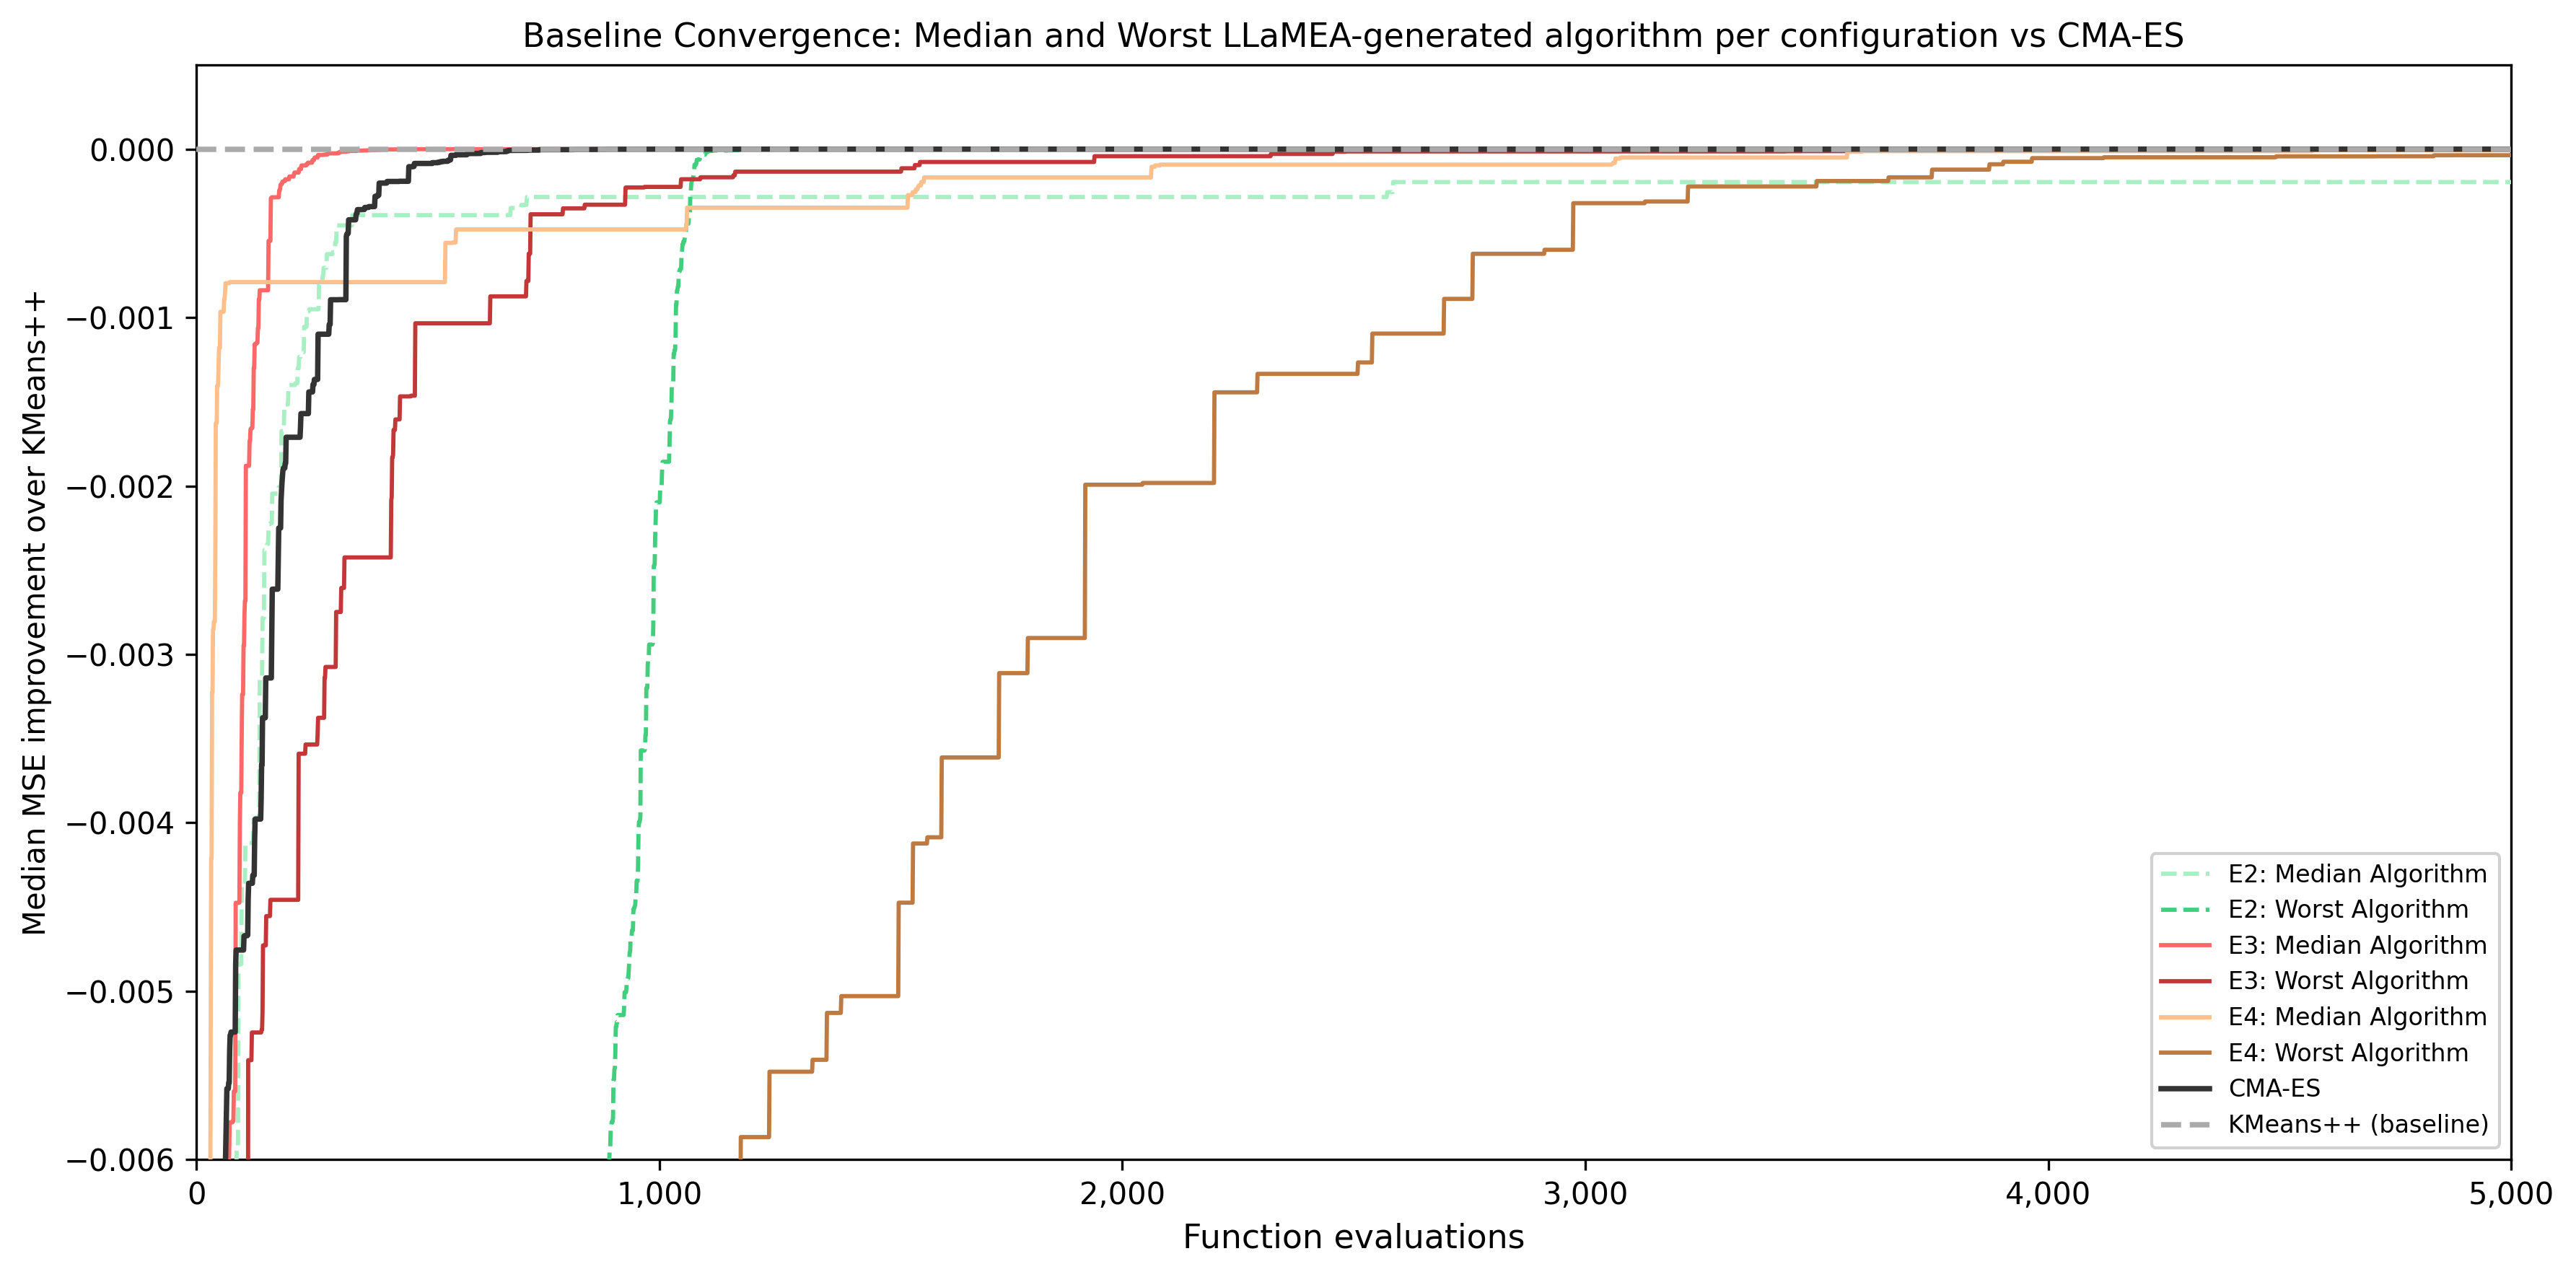


Algorithm                              Final imp     Best imp
──────────────────────────────────────────────────────────────
E2: Median Algorithm                    -0.00020     -0.00020
E2: Worst Algorithm                     -0.00000     -0.00000
E3: Median Algorithm                    -0.00000     -0.00000
E3: Worst Algorithm                     -0.00001     -0.00001
E4: Median Algorithm                    -0.00001     -0.00001
E4: Worst Algorithm                     -0.00004     -0.00004
CMA-ES                                  -0.00000     -0.00000
KMeans++ (baseline)                      0.00000      0.00000


In [38]:
# Bench mark convergence plot

import matplotlib.ticker as mticker

# Build cmaes_mean exactly as before
cmaes_conv = (
    cmaes_full
    .sort_values(["run_id", "fid", "k", "evaluations"])
    .copy()
)
cmaes_conv["best_imp_so_far"] = (
    cmaes_conv
    .groupby(["run_id", "fid", "k"])["imp_over_kmeans"]
    .cummax()
)
cmaes_agg = (
    cmaes_conv
    .groupby(["run_id", "evaluations"])["best_imp_so_far"]
    .median()
    .reset_index()
)
cmaes_mean = (
    cmaes_agg
    .groupby("evaluations")["best_imp_so_far"]
    .agg(median="median", q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75))
    .reset_index()
)
# SMOOTH = 10
# for col in ["median", "q25", "q75"]:
#     cmaes_mean[col] = cmaes_mean[col].rolling(SMOOTH, min_periods=1, center=True).mean()

CMAES_BUDGET = int(cmaes_mean["evaluations"].max())

# load and process LLaMEA benchmark IOH logs
BUDGET = 5000
DATA_ROOT = BASE_DIR / "Data_per_algorithm"

LLAMEA_CONFIGS = {
    # "E2_domain_knowledge_best" : "E2: Best Algorithm",
    "E2_domain_knowledge_middle"    : "E2: Median Algorithm",
    "E2_domain_knowledge_worst"  : "E2: Worst Algorithm",
    # "E3_no_domain_mutation_best": "E3: Best Algorithm",
    "E3_no_domain_mutation_middle"     : "E3: Median Algorithm",
    "E3_no_domain_mutation_worst"   : "E3: Worst Algorithm",
    # "E4_no_domain_warm_start_best" : "E4: Best Algorithm",
    "E4_no_domain_warm_start_middle" : "E4: Median Algorithm",
    "E4_no_domain_warm_start_worst" : "E4: Worst Algorithm",
    # "E6_domain_warm_start_best" : "E6: Best Algorithm",
    # "E6_domain_warm_start_middle" : "E6: Median Algorithm",
    # "E6_domain_warm_start_worst" : "E6: Worst Algorithm",
}

COLORS = {
     # E2 (green family)
    "E2_domain_knowledge_worst"  : "#42CF7D",  # light green
    "E2_domain_knowledge_middle" : "#A8EFC3",  # base green
    "E2_domain_knowledge_best"   : "#A8EFC3",  # dark green

    # E3 (red family)
    "E3_no_domain_mutation_worst"  : "#C23737",  # light red
    "E3_no_domain_mutation_middle" : "#FA6868",  # base red
    "E3_no_domain_mutation_best"   : "#FA6868",  # dark red

    # E4 (orange family)
    "E4_no_domain_warm_start_worst"  : "#BE7A41",  # light orange
    "E4_no_domain_warm_start_middle" : "#FDC08C",  # base orange
    "E4_no_domain_warm_start_best"   : "#FDC08C",  # dark orange

    # E6 (purple family)
    "E6_domain_warm_start_worst"  : "#8A58C7",  # light purple
    "E6_domain_warm_start_middle" : "#D3B3F0",  # base purple
    "E6_domain_warm_start_best"   : "#D3B3F0",  # dark purple
    "CMA-ES"                 : "#333333",
    "KMeans++"               : "#AAAAAA",
}

LINESTYLES = {
    "E2_domain_knowledge_best"    : "dashed",
    "E2_domain_knowledge_middle"    : "dashed",
    "E2_domain_knowledge_worst"    : "dashed",
    "E3_no_domain_mutation_best"  : "-",
    "E3_no_domain_mutation_middle": "-",
    "E3_no_domain_mutation_worst" : "-",
    "E4_no_domain_warm_start_best" : "-",
    "E4_no_domain_warm_start_middle" : "-",
    "E4_no_domain_warm_start_worst" : "-",
    "E6_domain_warm_start_best"     : "dashed",
    "E6_domain_warm_start_middle"   : "dashed",
    "E6_domain_warm_start_worst" : "dashed"
}


def parse_ioh_dat_v2(dat_path):
    """
    Parses flat CSV-style IOH logs with no run separators.
    Detects run boundaries by watching for the evaluation counter to reset.
    Returns DataFrame with columns: evaluations, mse, run_id
    """
    rows = []
    run_id = 1
    prev_eval = None

    with open(dat_path, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if not (line[0].isdigit() or line[0] == "-"):
                continue  # skip header row
            parts = line.split()
            if len(parts) < 2:
                continue
            try:
                evals = int(parts[0])
                mse   = float(parts[1])
            except ValueError:
                continue

            # counter reset = new run
            if prev_eval is not None and evals <= prev_eval:
                run_id += 1

            prev_eval = evals
            rows.append((evals, mse, run_id))

    if not rows:
        return None
    return pd.DataFrame(rows, columns=["evaluations", "mse", "run_id"])

# Load IOH logs for one config, return a convergence DataFrame
def load_and_build_curve(config_key, kmeans_base):
    pattern = os.path.join(DATA_ROOT, config_key, "fid1_k2", "*", "IOHprofiler_*.dat")
    probe = glob.glob(pattern)
    if not probe:
        print(f"  [skip] No logs found for {config_key}")
        return pd.DataFrame(), None
    alg_name = os.path.basename(os.path.dirname(probe[0]))

    all_dats = glob.glob(
        os.path.join(DATA_ROOT, config_key, "fid*_k*", alg_name, "IOHprofiler_*.dat")
    )

    frames = []
    for dat_path in all_dats:
        seg = [p for p in dat_path.replace("\\", "/").split("/")
               if p.startswith("fid") and "_k" in p]
        if not seg:
            continue
        fid = int(seg[0].split("_k")[0].replace("fid", ""))
        k   = int(seg[0].split("_k")[1])
        df  = parse_ioh_dat_v2(dat_path)
        if df is None:
            continue
        df["fid"] = fid
        df["k"]   = k
        frames.append(df)

    if not frames:
        return pd.DataFrame(), None

    full = pd.concat(frames, ignore_index=True)

    # Report actual budget used (median last evaluation across runs)
    actual_budget = int(
        full.groupby(["fid", "k", "run_id"])["evaluations"].max().median()
    )

    # cap to BUDGET (5000) — some algorithms slightly overshoot
    full = full[full["evaluations"] <= BUDGET].copy()

    full = full.sort_values(["fid", "k", "run_id", "evaluations"])
    full["best_mse_so_far"] = (
        full.groupby(["fid", "k", "run_id"])["mse"].cummin()
    )

    full = full.merge(kmeans_base, on=["fid", "k"], how="inner")
    if full.empty:
        return pd.DataFrame(), actual_budget
    full["imp_over_kmeans"] = full["baseline_mse"] - full["best_mse_so_far"]

    # forward-fill each (run_id, fid, k) for clarity
    eval_grid = pd.DataFrame({"evaluations": np.arange(1, actual_budget + 1)})

    records = []

    for (run_id, fid, k), grp in full.groupby(["run_id", "fid", "k"]):
        grp = grp.sort_values("evaluations")

        tmp = eval_grid.merge(
            grp[["evaluations", "imp_over_kmeans"]],
            on="evaluations",
            how="left"
        )

        tmp["imp_over_kmeans"] = tmp["imp_over_kmeans"].ffill()

        # before the first logged value, use the first available value
        tmp["imp_over_kmeans"] = tmp["imp_over_kmeans"].bfill()

        tmp["run_id"] = run_id
        tmp["fid"] = fid
        tmp["k"] = k

        records.append(tmp)

    dense = pd.concat(records, ignore_index=True)

    per_run = (
        dense.groupby(["run_id", "evaluations"])["imp_over_kmeans"]
        .median().reset_index()
    )
    curve = (
        per_run.groupby("evaluations")["imp_over_kmeans"]
        .agg(median="median", q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75))
        .reset_index()
    )
    return curve, actual_budget


# load each convergence for llamea
llamea_curves = {}
actual_budgets = {}
for config_key, label in LLAMEA_CONFIGS.items():
    print(f"Loading {label} ...", end=" ")
    curve, budget_used = load_and_build_curve(config_key, kmeans_base)
    if curve.empty:
        continue
    llamea_curves[config_key] = curve
    actual_budgets[config_key] = budget_used
    print(f"ok  |  actual budget={budget_used}  "
          f"final={curve['median'].iloc[-1]:.5f}  "
          f"best={curve['median'].max():.5f}")

# plot llamea curve
fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

for config_key, label in LLAMEA_CONFIGS.items():
    if config_key not in llamea_curves:
        continue
    curve = llamea_curves[config_key]
    ax.plot(
        curve["evaluations"], curve["median"],
        color=COLORS[config_key],
        linestyle=LINESTYLES[config_key],
        linewidth=1.4,
        label=label,
        zorder=3,
    )

# CMA-ES directly comparable to the algorithms because both run for 5000 evals
ax.plot(
    cmaes_mean["evaluations"], cmaes_mean["median"],
    color=COLORS["CMA-ES"],
    linestyle="-",
    linewidth=1.8,
    label="CMA-ES",
    zorder=4,
)

ax.axhline(
    y=0,
    color=COLORS["KMeans++"],
    linestyle="dashed",
    linewidth=1.8,
    label="KMeans++ (baseline)",
    zorder=5,
)


ax.set_xlabel("Function evaluations", fontsize=11)
ax.set_ylabel("Median MSE improvement over KMeans++", fontsize=10)
ax.set_title(
    "Baseline Convergence: Median and Worst LLaMEA-generated algorithm per configuration vs CMA-ES",
    fontsize=11,
)

ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.legend(fontsize=8, loc="lower right", framealpha=0.9)

# Force the y-axis on every axis in the figure
for a in fig.axes:
    a.set_ylim(-0.006, 0.0005)
ax.set_xlim(0, 5000)

plt.tight_layout()
plt.savefig("benchmark_convergence_new.png", dpi=300, bbox_inches="tight")
plt.show()



# summary table with final imp
print(f"\n{'Algorithm':<35} {'Final imp':>12} {'Best imp':>12}")
print("─" * 62)
for config_key, label in LLAMEA_CONFIGS.items():
    if config_key not in llamea_curves:
        print(f"{label:<35} {'(no data)':>12}")
        continue
    c = llamea_curves[config_key]
    print(f"{label:<35} {c['median'].iloc[-1]:>12.5f} {c['median'].max():>12.5f}")
print(f"{'CMA-ES':<35} {cmaes_mean['median'].iloc[-1]:>12.5f} {cmaes_mean['median'].max():>12.5f}")
print(f"{'KMeans++ (baseline)':<35} {'0.00000':>12} {'0.00000':>12}")

In [39]:
# load plots for near baseline zoom (and exact algs)

LLAMEA_CONFIGS = {
    "E1_no_domain_knowledge" : "E1: ChaoticLocalSearch",
    "E2_domain_knowledge"    : "E2: SpectralClusteringOptimizer",
    "E3_no_domain_mutation"  : "E3: AdaptiveESClustering",
    "E4_no_domain_warm_start": "E4: AdaptiveLocalSearch",
    "E5_domain_mutation"     : "E5: SymmetricCMAES",
    "E6_domain_warm_start"   : "E6: QuantumAdaptiveLocalSearch",
}

focus_configs = [
    "E2_domain_knowledge",
    "E3_no_domain_mutation",
    "E4_no_domain_warm_start",
    "E6_domain_warm_start"

]

COLORS.update({
    "E1_no_domain_knowledge":  "#7F77DD",
    "E2_domain_knowledge":     "#42CF7D",
    "E3_no_domain_mutation":   "#D80404",
    "E4_no_domain_warm_start": "#FB7507",
    "E5_domain_mutation":      "#5F5F5F",
    "E6_domain_warm_start":    "#8A58C7",
})

LINESTYLES.update({
    "E1_no_domain_knowledge":  "-",
    "E2_domain_knowledge":     "dashed",
    "E3_no_domain_mutation":   "-",
    "E4_no_domain_warm_start": "-",
    "E5_domain_mutation":      "-",
    "E6_domain_warm_start":    "dashed",
})

llamea_curves = {}
actual_budgets = {}

for config_key in focus_configs:

    print(
        f"Loading {LLAMEA_CONFIGS[config_key]} ...",
        end=" "
    )

    curve, budget_used = load_and_build_curve(
        config_key,
        kmeans_base
    )

    if curve.empty:
        print("NO DATA")
        continue

    llamea_curves[config_key] = curve
    actual_budgets[config_key] = budget_used

    print(
        f"ok | "
        f"actual budget={budget_used} | "
        f"final={curve['median'].iloc[-1]:.6f} | "
        f"best={curve['median'].max():.6f}"
    )


print("\nLoaded curves:")
for config_key in llamea_curves:
    print(
        f"  {config_key}: "
        f"{len(llamea_curves[config_key])} evaluation points"
    )

Loading E2: SpectralClusteringOptimizer ... ok | actual budget=5005 | final=-0.000011 | best=-0.000011
Loading E3: AdaptiveESClustering ... ok | actual budget=5000 | final=-0.000148 | best=-0.000148
Loading E4: AdaptiveLocalSearch ... ok | actual budget=5000 | final=-0.000115 | best=-0.000115
Loading E6: QuantumAdaptiveLocalSearch ... ok | actual budget=5000 | final=-0.000008 | best=-0.000008

Loaded curves:
  E2_domain_knowledge: 5005 evaluation points
  E3_no_domain_mutation: 5000 evaluation points
  E4_no_domain_warm_start: 5000 evaluation points
  E6_domain_warm_start: 5000 evaluation points


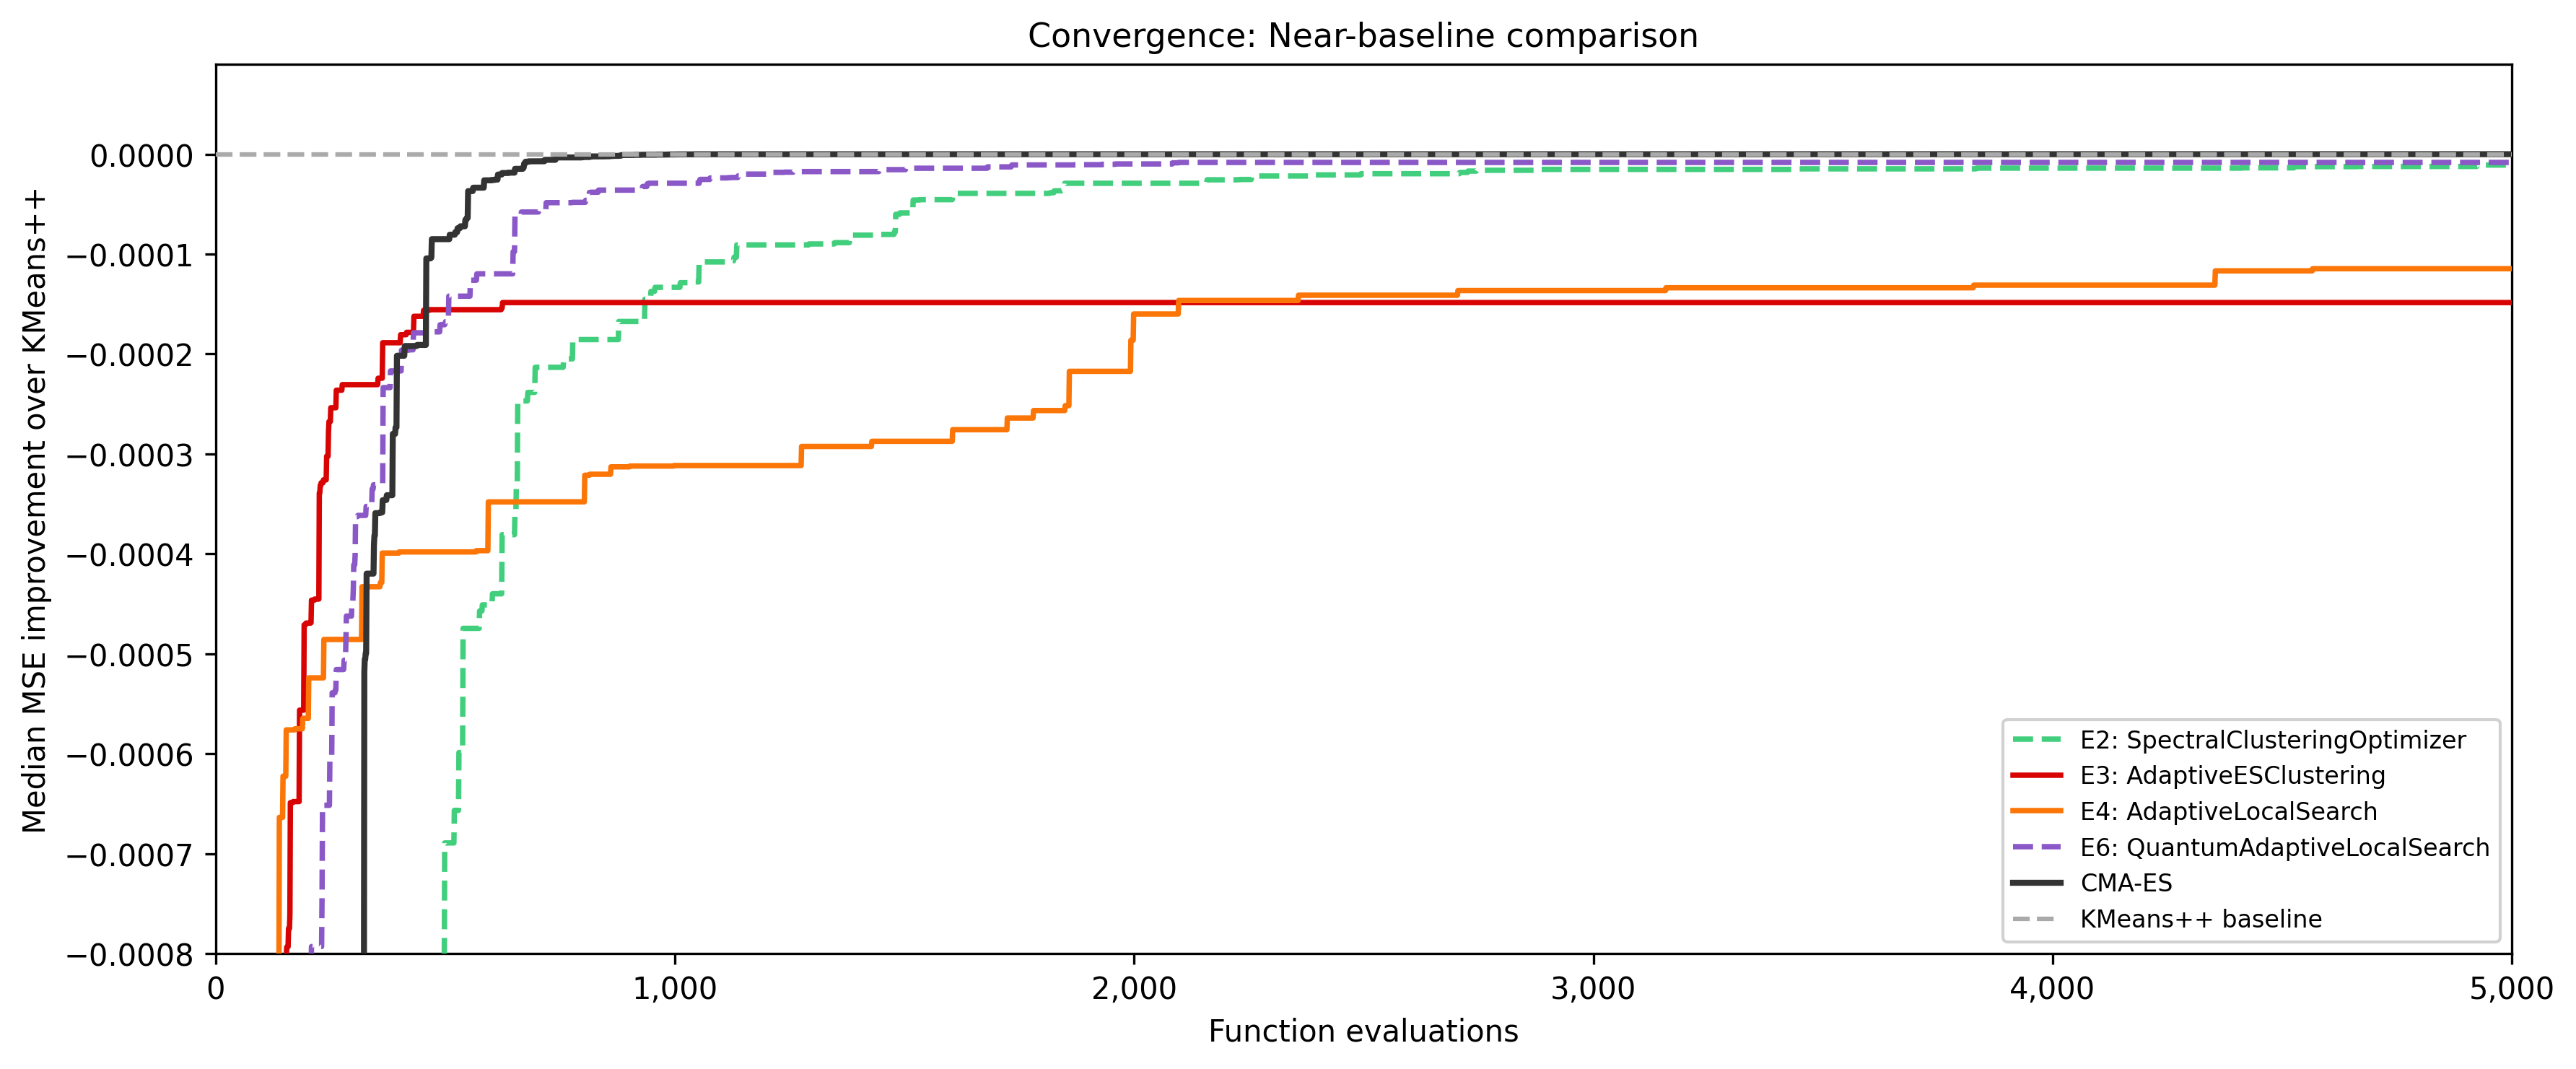

In [40]:
# plot convergence of the algorithm values 
fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

for config_key in focus_configs:

    if config_key not in llamea_curves:
        print(f"Skipping {config_key}: curve was not loaded")
        continue

    curve = llamea_curves[config_key]

    ax.plot(
        curve["evaluations"],
        curve["median"],
        color=COLORS[config_key],
        linestyle=LINESTYLES[config_key],
        linewidth=1.8,
        label=LLAMEA_CONFIGS[config_key],
        zorder=3,
    )

ax.plot(
    cmaes_mean["evaluations"],
    cmaes_mean["median"],
    color=COLORS["CMA-ES"],
    linestyle="-",
    linewidth=2.0,
    label="CMA-ES",
    zorder=4,
)

ax.axhline(
    y=0,
    color=COLORS["KMeans++"],
    linestyle="dashed",
    linewidth=1.5,
    label="KMeans++ baseline",
    zorder=5,
)

ax.set_xlabel("Function evaluations", fontsize=10)
ax.set_ylabel("Median MSE improvement over KMeans++", fontsize=10)
ax.set_title(
    "Convergence: Near-baseline comparison",
    fontsize=11,
)

ax.set_xlim(0, 5000)
ax.set_ylim(-0.0008, 0.00009)

ax.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"{int(x):,}")
)

ax.legend(
    fontsize=8,
    loc="lower right",
    framealpha=0.9
)

plt.tight_layout(rect=[0, 0.08, 1, 0.92])
plt.savefig(
    "benchmark_convergence_two_panel.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Selected best overall: E6: Domain + warm start / QuantumAdaptiveMultiStrategyLocalSearch  (fitness=-0.000568)

LLaMEA median final-best MSE:


k,2,3,5,10
fid,,,,
1,0.044077,0.031844,0.015552,0.005641
2,0.029043,0.017616,0.010674,0.005464
3,0.030364,0.020230,0.007936,0.003512
4,0.026849,0.013374,0.008202,0.003637
5,0.046361,0.026108,0.014833,0.007395
6,0.009251,0.004211,0.002238,0.001029
7,0.050613,0.025976,0.014621,0.007217
8,0.077863,0.042336,0.009230,0.004662
9,0.015294,0.006986,0.003008,0.002030



CMA-ES median final-best MSE:


k,2,3,5,10
fid,,,,
1,0.044068,0.029825,0.014901,0.004607
2,0.029028,0.017608,0.010629,0.004508
3,0.030357,0.020139,0.007863,0.002298
4,0.026846,0.013371,0.007702,0.003012
5,0.046356,0.026102,0.014797,0.006335
6,0.009248,0.004209,0.002042,0.000913
7,0.050610,0.025972,0.014584,0.006272
8,0.077859,0.042327,0.008411,0.003472
9,0.015287,0.006952,0.002956,0.001584


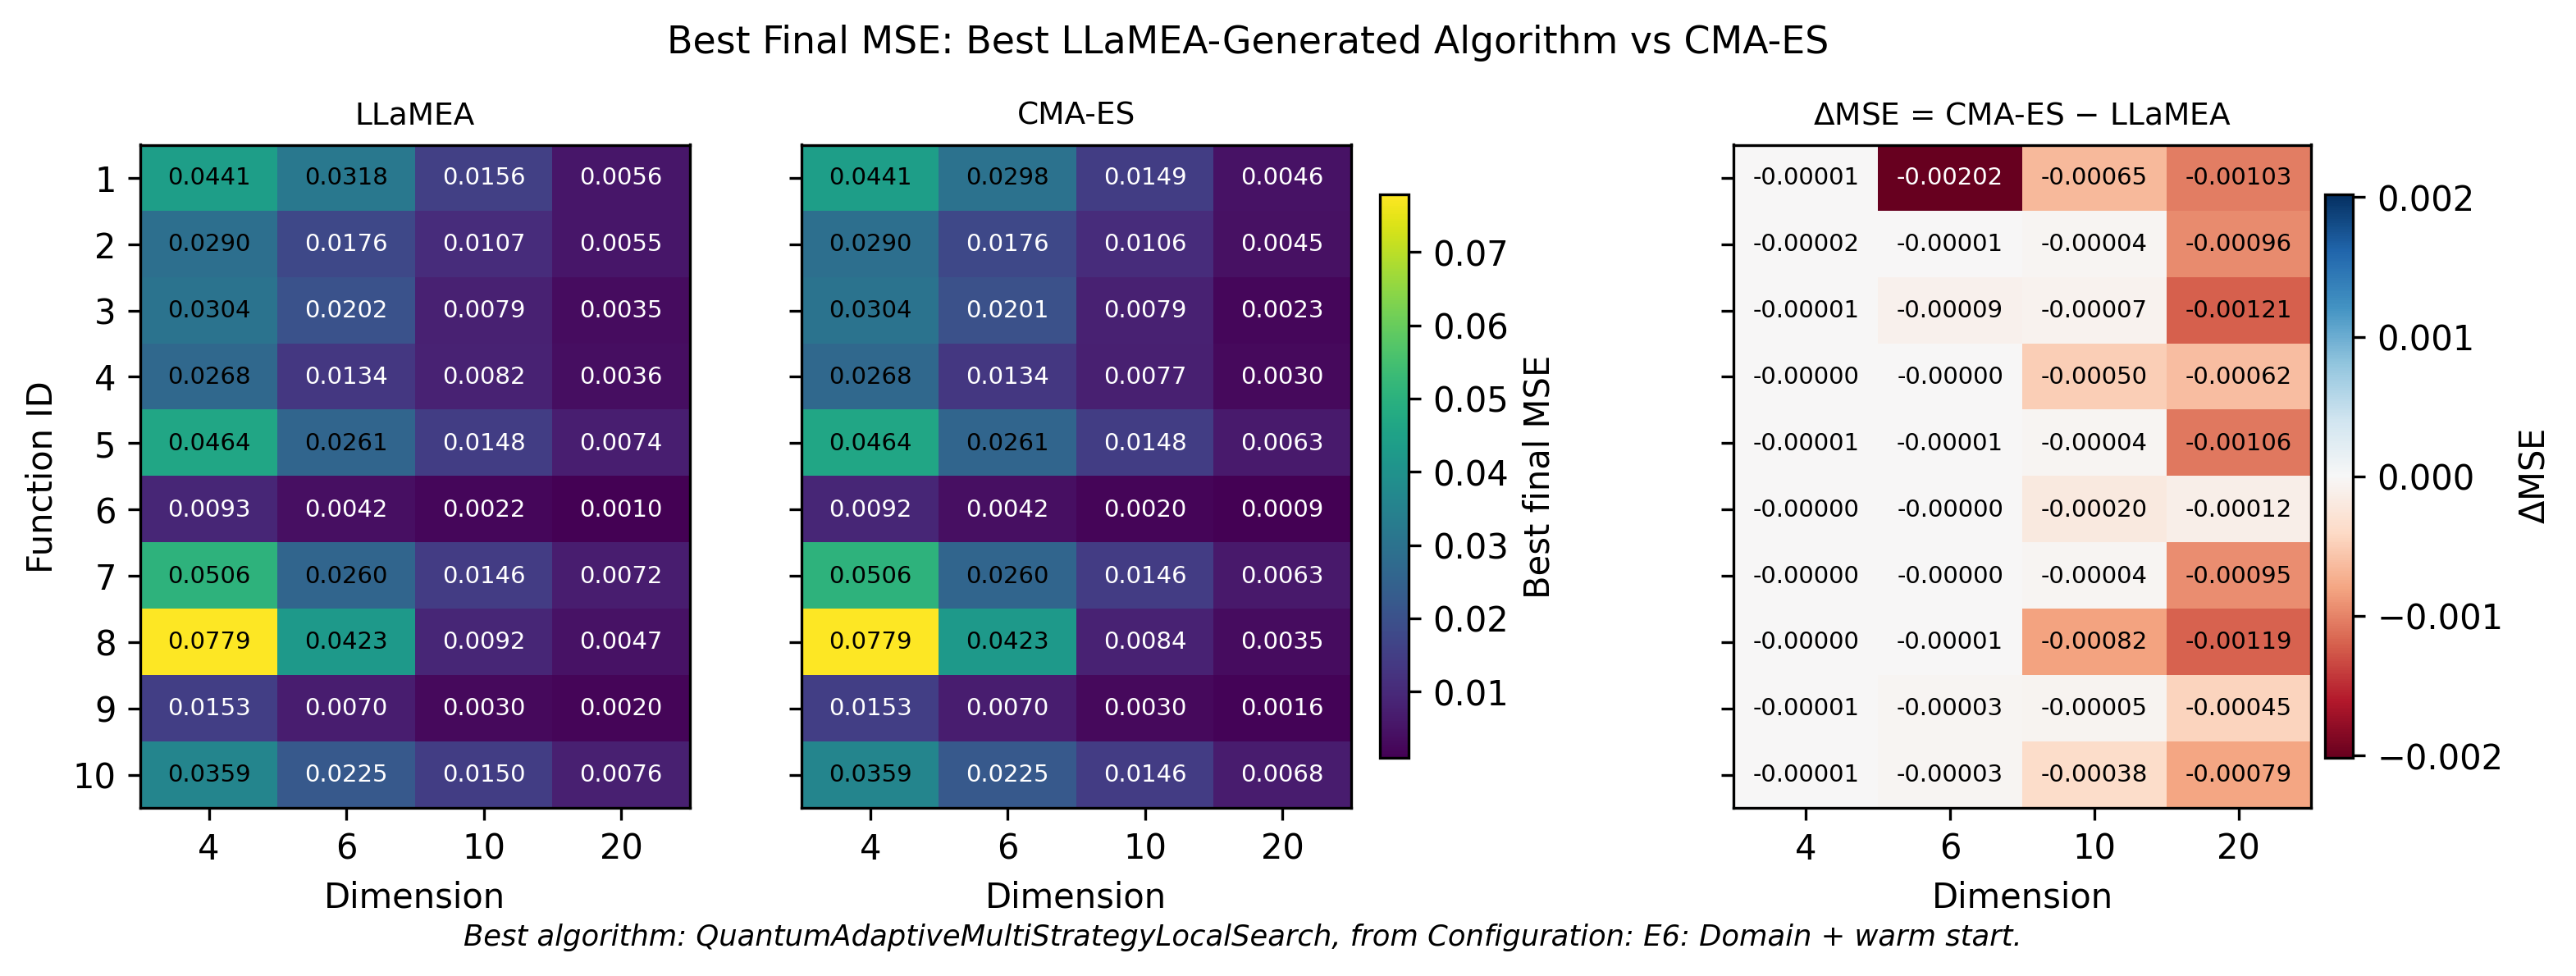

{'llamea': k          2         3         5         10
 fid                                        
 1    0.044077  0.031844  0.015552  0.005641
 2    0.029043  0.017616  0.010674  0.005464
 3    0.030364  0.020230  0.007936  0.003512
 4    0.026849  0.013374  0.008202  0.003637
 5    0.046361  0.026108  0.014833  0.007395
 6    0.009251  0.004211  0.002238  0.001029
 7    0.050613  0.025976  0.014621  0.007217
 8    0.077863  0.042336  0.009230  0.004662
 9    0.015294  0.006986  0.003008  0.002030
 10   0.035901  0.022519  0.015022  0.007609,
 'cmaes': k          2         3         5         10
 fid                                        
 1    0.044068  0.029825  0.014901  0.004607
 2    0.029028  0.017608  0.010629  0.004508
 3    0.030357  0.020139  0.007863  0.002298
 4    0.026846  0.013371  0.007702  0.003012
 5    0.046356  0.026102  0.014797  0.006335
 6    0.009248  0.004209  0.002042  0.000913
 7    0.050610  0.025972  0.014584  0.006272
 8    0.077859  0.042327  0.008411 

In [41]:
# LLaMEA algorithm ACROSS ALL E's VS CMA-ES  (fixed)

import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_ROOT = BASE_DIR / "Data_per_algorithm"
BUDGET    = 5000

LLAMEA_CONFIGS = {
    "E1_no_domain_knowledge" : "E1: No domain knowledge",
    "E2_domain_knowledge"    : "E2: Domain knowledge",
    "E3_no_domain_mutation"  : "E3: No Domain + mutation",
    "E4_no_domain_warm_start": "E4: No Domain + warm start",
    "E5_domain_mutation"     : "E5: Domain + mutation",
    "E6_domain_warm_start"   : "E6: Domain + warm start",
}

BEST_SELECTED_PER_E = pd.DataFrame([
    {
        "config_key"  : "E1_no_domain_knowledge",
        "label"       : "E1: No domain knowledge",
        "best_fitness": -0.004464,
        "algo_name"   : "ChaoticLocalSearch",
        "source"      : results_path / "without_domain_knowledge" / "run-LLaMEA-CLUSTERING-0" / "log.jsonl",
    },
    {
        "config_key"  : "E2_domain_knowledge",
        "label"       : "E2: Domain knowledge",
        "best_fitness": -0.004379,
        "algo_name"   : "SpectralClusteringOptimizer",
        "source"      : results_path / "domain_knowledge" / "run-LLaMEA-CLUSTERING-0" / "log.jsonl",
    },
    {
        "config_key"  : "E3_no_domain_mutation",
        "label"       : "E3: No Domain + mutation",
        "best_fitness": -0.004475,
        "algo_name"   : "AdaptiveESClustering",
        "source"      : results_path / "mutation_5_runs_elitism_on" / "run-LLaMEA-CLUSTERING-4" / "log.jsonl",
    },
    {
        "config_key"  : "E4_no_domain_warm_start",
        "label"       : "E4: No Domain + warm start",
        "best_fitness": -0.002583,
        "algo_name"   : "AdaptiveLocalSearch",
        "source"      : results_path / "warm_start_5_runs" / "run-LLaMEA-CLUSTERING-2" / "log.jsonl",
    },
    {
        "config_key"  : "E5_domain_mutation",
        "label"       : "E5: Domain + exemplar-injection",
        "best_fitness": -0.002939,
        "algo_name"   : "SymmetricCMAES",
        "source"      : results_path / "5_runs_mutation_prompts_WITH_DOMAIN_KNOWLEDGE" / "run-LLaMEA-CLUSTERING-1" / "log.jsonl",
    },
    {
        "config_key"  : "E6_domain_warm_start",
        "label"       : "E6: Domain + warm start",
        "best_fitness": -0.0005679,  
        "algo_name"   : "QuantumAdaptiveMultiStrategyLocalSearch",
        "source"      : results_path / "5_runs_warm_start_WITH_DOMAIN_KNOWLEDGE" / "run-LLaMEA-CLUSTERING-1" / "log.jsonl",
    },
])

best_selected_row = (
    BEST_SELECTED_PER_E
    .sort_values("best_fitness", ascending=False)   # higher = less negative = better
    .iloc[0]
)

BEST_CONFIG_KEY   = best_selected_row["config_key"]
BEST_CONFIG_LABEL = best_selected_row["label"]
BEST_ALGO_NAME    = best_selected_row["algo_name"]
BEST_FITNESS      = best_selected_row["best_fitness"]

print(f"Selected best overall: {BEST_CONFIG_LABEL} / {BEST_ALGO_NAME}  (fitness={BEST_FITNESS:.6f})")


# make sure ioh data is readable 
def parse_ioh_dat_v2(dat_path):
    rows = []
    run_id   = 1
    prev_eval = None
    with open(dat_path, "r") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if not (line[0].isdigit() or line[0] == "-"):
                continue
            parts = line.split()
            if len(parts) < 2:
                continue
            try:
                evals = int(parts[0])
                mse   = float(parts[1])
            except ValueError:
                continue
            if prev_eval is not None and evals <= prev_eval:
                run_id += 1
            prev_eval = evals
            rows.append((evals, mse, run_id))
    if not rows:
        return None
    return pd.DataFrame(rows, columns=["evaluations", "mse", "run_id"])


def parse_fid_k(path_str):
    parts = path_str.replace("\\", "/").split("/")
    seg   = next((p for p in parts if p.startswith("fid") and "_k" in p), None)
    if seg is None:
        return None, None
    fid = int(seg.split("_k")[0].replace("fid", ""))
    k   = int(seg.split("_k")[1].split("-")[0])  
    return fid, k


#  load LLaMEA benchmarks logs with median final-best MSE 
def load_llamea_median_mse(config_key):
    all_dats = glob.glob(
        os.path.join(DATA_ROOT, config_key, "fid*_k*", "*", "IOHprofiler_*.dat")
    )
    if not all_dats:
        raise ValueError(f"No IOH logs found for {config_key}")

    frames = []
    for dat_path in all_dats:
        fid, k = parse_fid_k(dat_path)
        if fid is None:
            continue

        df = parse_ioh_dat_v2(dat_path)
        if df is None or df.empty:
            continue

        df = df[df["evaluations"] <= BUDGET].copy()
        if df.empty:
            continue

        # best MSE reached within budget, per run
        per_run = (
            df.groupby("run_id", as_index=False)
            .agg(final_best_mse=("mse", "min"))
        )
        per_run["fid"] = fid
        per_run["k"]   = k
        frames.append(per_run)

    if not frames:
        raise ValueError(f"No parseable logs for {config_key}")

    full = pd.concat(frames, ignore_index=True)

    # median across runs per (fid, k) 
    summary = (
        full.groupby(["fid", "k"], as_index=False)
        .agg(median_best_mse=("final_best_mse", "median"))
    )
    return summary.pivot(index="fid", columns="k", values="median_best_mse")


# build CMA-ES median final-best MSE per (fid, k) 
def build_cmaes_median_mse(cmaes_full):

    col = "best_mse_so_far" if "best_mse_so_far" in cmaes_full.columns else "mse"

    tmp = cmaes_full.copy()
    if "evaluations" in tmp.columns:
        tmp = tmp[tmp["evaluations"] <= BUDGET]

    per_run = (
        tmp.dropna(subset=[col])
        .groupby(["fid", "k", "run_id"], as_index=False)
        .agg(final_best_mse=(col, "min"))
    )
    summary = (
        per_run.groupby(["fid", "k"], as_index=False)
        .agg(median_best_mse=("final_best_mse", "median"))
    )
    return summary.pivot(index="fid", columns="k", values="median_best_mse")


llamea_pivot = load_llamea_median_mse(BEST_CONFIG_KEY)
cmaes_pivot  = build_cmaes_median_mse(cmaes_full)

print("\nLLaMEA median final-best MSE:")
display(llamea_pivot)
print("\nCMA-ES median final-best MSE:")
display(cmaes_pivot)


# make sure that the text is visible 
def get_text_color(value, vmin, vmax, cmap_name):
    if vmax <= vmin:
        normed = 0.5
    else:
        normed = (value - vmin) / (vmax - vmin)

    if cmap_name == "viridis":
        return "white" if normed < 0.3 else "black"
    elif cmap_name == "RdBu":
        return "white" if (normed < 0.15 or normed > 0.95) else "black"
    else:
        return "white" if normed < 0.5 else "black"


def plot_heatmap(llamea_pivot, cmaes_pivot):
    all_fids = sorted(set(llamea_pivot.index) | set(cmaes_pivot.index))
    all_ks   = sorted(set(llamea_pivot.columns) | set(cmaes_pivot.columns))

    llamea_piv = llamea_pivot.reindex(index=all_fids, columns=all_ks)
    cmaes_piv  = cmaes_pivot.reindex(index=all_fids, columns=all_ks)

    # positive ΔMSE means LLaMEA has lower MSE than CMA-ES
    diff_piv = cmaes_piv - llamea_piv

    lv = llamea_piv.values.astype(float)
    cv = cmaes_piv.values.astype(float)
    dv = diff_piv.values.astype(float)

    # shared colour scale for raw MSE panels
    mse_all = np.concatenate([lv.ravel(), cv.ravel()])
    mse_all = mse_all[np.isfinite(mse_all)]

    if len(mse_all) == 0:
        raise ValueError("No finite MSE values available for plotting.")

    mse_vmin, mse_vmax = np.nanmin(mse_all), np.nanmax(mse_all)

    # symmetric colour scale for ΔMSE
    diff_finite = dv[np.isfinite(dv)]

    if len(diff_finite) == 0:
        raise ValueError("No finite ΔMSE values available for plotting.")

    diff_absmax = max(np.nanmax(np.abs(diff_finite)), 1e-12)
    diff_vmin, diff_vmax = -diff_absmax, diff_absmax


    fig, axes = plt.subplots(
        1,
        3,
        figsize=(12, 3.5),
        dpi=300,
        sharey=True,
        gridspec_kw={"width_ratios": [1, 1, 1.05]}
    )

    panels = [
        {
            "ax": axes[0],
            "values": lv,
            "title": f"LLaMEA",
            "cmap": "viridis",
            "vmin": mse_vmin,
            "vmax": mse_vmax,
            "fmt": "{:.4f}",
        },
        {
            "ax": axes[1],
            "values": cv,
            "title": "CMA-ES",
            "cmap": "viridis",
            "vmin": mse_vmin,
            "vmax": mse_vmax,
            "fmt": "{:.4f}",
        },
        {
            "ax": axes[2],
            "values": dv,
            "title": r"$\Delta$MSE = CMA-ES $-$ LLaMEA",
            "cmap": "RdBu",
            "vmin": diff_vmin,
            "vmax": diff_vmax,
            "fmt": "{:+.5f}",
        },
    ]

    mse_im = None
    diff_im = None

    for panel in panels:
        ax = panel["ax"]
        vals = panel["values"]
        cmap_name = panel["cmap"]

        im = ax.imshow(
            vals,
            aspect="auto",
            cmap=cmap_name,
            vmin=panel["vmin"],
            vmax=panel["vmax"]
        )

        if cmap_name == "viridis" and mse_im is None:
            mse_im = im

        if cmap_name == "RdBu":
            diff_im = im

        ax.set_title(panel["title"], fontsize=9)
        ax.set_xlabel("Dimension", fontsize=10)

        ax.set_xticks(np.arange(len(all_ks)))
        ax.set_xticklabels([str(k*2) for k in all_ks])

        ax.set_yticks(np.arange(len(all_fids)))
        ax.set_yticklabels(all_fids)

        # make sure text is readable
        for i in range(vals.shape[0]):
            for j in range(vals.shape[1]):
                value = vals[i, j]

                if np.isfinite(value):
                    text_color = get_text_color(
                        value,
                        panel["vmin"],
                        panel["vmax"],
                        cmap_name
                    )

                    ax.text(
                        j,
                        i,
                        panel["fmt"].format(value),
                        ha="center",
                        va="center",
                        fontsize=7,
                        color=text_color
                    )

    axes[0].set_ylabel("Function ID", fontsize=10)
    axes[1].tick_params(labelleft=False)
    axes[2].tick_params(labelleft=False)

    fig.suptitle(
        "Best Final MSE: Best LLaMEA-Generated Algorithm vs CMA-ES",
        fontsize=11,
        y=1.02
    )

    # colourbars in the same style 
    cbar_mse = fig.colorbar(
        mse_im,
        ax=axes[:2],
        shrink=0.85,
        pad=0.02
    )
    cbar_mse.set_label("Best final MSE")

    cbar_diff = fig.colorbar(
        diff_im,
        ax=axes[2],
        shrink=0.85,
        pad=0.02
    )
    cbar_diff.set_label(r"$\Delta$MSE")

    fig.text(
        0.5,
        -0.05,
        (
            f"Best algorithm: {BEST_ALGO_NAME}, from Configuration: {BEST_CONFIG_LABEL}. "
        ),
        ha="center",
        fontsize=8.5,
        style="italic"
    )

    plt.show()

    return {
        "llamea": llamea_piv,
        "cmaes": cmaes_piv,
        "diff": diff_piv,
    }


plot_heatmap(llamea_pivot, cmaes_pivot)

In [42]:
# paired wilcoxon signed rank test: benchmark MSE

from scipy.stats import wilcoxon
import numpy as np
import pandas as pd

# median across 25 runs first this is the stable estimate of each
# config's performance on each problem, removing seed noise.

def load_median_per_fid_k(config_keys):
    frames = []
    for config_key in config_keys:
        all_dats = glob.glob(
            os.path.join(DATA_ROOT, config_key, "fid*_k*", "*", "IOHprofiler_*.dat")
        )
        for dat_path in all_dats:
            fid, k = parse_fid_k(dat_path)
            if fid is None:
                continue
            df = parse_ioh_dat_v2(dat_path)
            if df is None or df.empty:
                continue
            df = df[df["evaluations"] <= BUDGET].copy()
            if df.empty:
                continue
            per_run = (
                df.groupby("run_id", as_index=False)
                .agg(final_best_mse=("mse", "min"))
            )
            median_mse = float(per_run["final_best_mse"].median())
            frames.append({
                "config" : config_key,
                "fid"    : fid,
                "k"      : k,
                "median_final_mse": median_mse,
            })

    return pd.DataFrame(frames)


NO_DOMAIN_CONFIGS = [
    "E1_no_domain_knowledge",
    "E3_no_domain_mutation",
    "E4_no_domain_warm_start",
]
DOMAIN_CONFIGS = [
    "E2_domain_knowledge",
    "E5_domain_mutation",
    "E6_domain_warm_start",
]

# prompt-strategy pairs for pairing
PAIRS = [
    ("E1_no_domain_knowledge", "E2_domain_knowledge",     "Baseline"),
    ("E3_no_domain_mutation",  "E5_domain_mutation",      "Mutation"),
    ("E4_no_domain_warm_start","E6_domain_warm_start",    "Warm start"),
]

print("Loading benchmark logs ...")
no_domain_long = load_median_per_fid_k(NO_DOMAIN_CONFIGS)
domain_long    = load_median_per_fid_k(DOMAIN_CONFIGS)

# create the pair for the analysis
paired_rows = []
for no_dom_key, dom_key, strategy in PAIRS:
    nd = no_domain_long[no_domain_long["config"] == no_dom_key][
        ["fid", "k", "median_final_mse"]
    ].rename(columns={"median_final_mse": "mse_no_domain"})

    d  = domain_long[domain_long["config"] == dom_key][
        ["fid", "k", "median_final_mse"]
    ].rename(columns={"median_final_mse": "mse_domain"})

    merged = nd.merge(d, on=["fid", "k"], how="inner")
    merged["strategy"] = strategy
    merged["delta"]    = merged["mse_no_domain"] - merged["mse_domain"]
    # positive delta = no-domain has HIGHER MSE, domain wins
    paired_rows.append(merged)

paired_df = pd.concat(paired_rows, ignore_index=True)

print(f"\nPaired observations: {len(paired_df)}")
print(f"  ({len(PAIRS)} strategy pairs × 10 fids × 4 k = {len(PAIRS)*40} expected)")
print(f"  Positive delta (domain wins): {(paired_df['delta'] > 0).sum()}")
print(f"  Negative delta (no-domain wins): {(paired_df['delta'] < 0).sum()}")
print(f"  Ties: {(paired_df['delta'] == 0).sum()}")

# paired Wilcoxon signed-rank test 
deltas = paired_df["delta"].dropna().values

W_stat, p_two  = wilcoxon(deltas, alternative="two-sided")
W_less, p_less = wilcoxon(deltas, alternative="less")   # domain < no-domain MSE

n_pairs = len(deltas)
# Rank-biserial for signed-rank: r_rb = W+ / (n*(n+1)/2)  — or via effect
# Standard formula: r_rb = 1 - (4*W) / (n*(n+1))  where W = min(W+, W-)
# But scipy returns W = sum of ranks of positive differences
# Simpler: r_rb = (W_pos - W_neg) / (W_pos + W_neg)
# We can recover W_pos from scipy output and n
W_max   = n_pairs * (n_pairs + 1) / 2
r_rb    = 1 - (2 * W_stat) / W_max


print(f"Paired Wilcoxon signed-rank test (benchmark MSE)")
print(f"\n  Pairs: (E1,E2), (E3,E5), (E4,E6) × 40 problems")
print(f"  n pairs = {n_pairs}")
print(f"  Delta = MSE_no_domain - MSE_domain")
print(f"  (positive = domain knowledge reduces MSE)")

print(f"\n  W    = {W_stat:.1f}")
print(f"  p    = {p_two:.4f}  (two-sided)")
print(f"  p    = {p_less:.4f}  (one-sided: domain < no-domain MSE)")
print(f"  r_rb = {r_rb:.4f}")


abs_r = abs(r_rb)
effect = ("negligible" if abs_r < 0.1 else
          "small"      if abs_r < 0.3 else
          "medium"     if abs_r < 0.5 else "large")
direction = ("domain reduces MSE" if r_rb > 0
             else "no-domain reduces MSE")

print(f"\n  Effect size: |r_rb| = {abs_r:.4f} → {effect}")
print(f"  Direction  : {direction}")
print(f"\n  Median delta: {np.median(deltas):+.6f}")
print(f"  Median MSE no-domain : {paired_df['mse_no_domain'].median():.6f}")
print(f"  Median MSE domain    : {paired_df['mse_domain'].median():.6f}")

# per prompt strat
print(f"\nPer prompt-strategy breakdown:")
print(f"  {'Strategy':<12} {'n':>4} {'Median delta':>14} "
      f"{'Domain wins':>12} {'No-domain wins':>15}")

for strategy, grp in paired_df.groupby("strategy"):
    d = grp["delta"]
    print(f"  {strategy:<12} {len(d):>4} {d.median():>+14.6f} "
          f"{(d>0).sum():>12} {(d<0).sum():>15}")

Loading benchmark logs ...

Paired observations: 120
  (3 strategy pairs × 10 fids × 4 k = 120 expected)
  Positive delta (domain wins): 79
  Negative delta (no-domain wins): 41
  Ties: 0
Paired Wilcoxon signed-rank test (benchmark MSE)

  Pairs: (E1,E2), (E3,E5), (E4,E6) × 40 problems
  n pairs = 120
  Delta = MSE_no_domain - MSE_domain
  (positive = domain knowledge reduces MSE)

  W    = 2948.0
  p    = 0.0741  (two-sided)
  p    = 0.9630  (one-sided: domain < no-domain MSE)
  r_rb = 0.1879

  Effect size: |r_rb| = 0.1879 → small
  Direction  : domain reduces MSE

  Median delta: +0.000689
  Median MSE no-domain : 0.015426
  Median MSE domain    : 0.014807

Per prompt-strategy breakdown:
  Strategy        n   Median delta  Domain wins  No-domain wins
  Baseline       40      +0.003230           40               0
  Mutation       40      -0.002917            0              40
  Warm start     40      +0.000954           39               1


In [43]:
# Table of performance

stoch_rows = []

for config_key, label in LLAMEA_CONFIGS.items():
    all_dats = glob.glob(
        os.path.join(DATA_ROOT, config_key, "fid*_k*", "*", "IOHprofiler_*.dat")
    )
    if not all_dats:
        print(f"  [skip] {label}")
        continue

    frames = []
    for dat_path in all_dats:
        fid, k = parse_fid_k(dat_path)
        if fid is None:
            continue
        df = parse_ioh_dat_v2(dat_path)
        if df is None or df.empty:
            continue
        df = df[df["evaluations"] <= BUDGET].copy()
        if df.empty:
            continue

        # best MSE per run → imp_over_kmeans per run
        base_row = kmeans_base[
            (kmeans_base["fid"] == fid) & (kmeans_base["k"] == k)
        ]
        if base_row.empty:
            continue
        base_mse = float(base_row["baseline_mse"].iloc[0])

        per_run = (
            df.groupby("run_id")["mse"]
            .min()
            .apply(lambda m: base_mse - m)
        )
        per_run_df = per_run.reset_index()
        per_run_df.columns = ["run_id", "imp_over_kmeans"]
        per_run_df["fid"] = fid
        per_run_df["k"]   = k
        frames.append(per_run_df)

    if not frames:
        continue

    full = pd.concat(frames, ignore_index=True)

    # agg across (fid, k): median over runs, then summarise
    per_run_agg = (
        full.groupby("run_id")["imp_over_kmeans"]
        .median()
        .reset_index()
    )

    best_run   = float(per_run_agg["imp_over_kmeans"].max())
    median_run = float(per_run_agg["imp_over_kmeans"].median())
    worst_run  = float(per_run_agg["imp_over_kmeans"].min())
    spread     = best_run - worst_run
    ratio      = abs(best_run) / abs(median_run) if median_run != 0 else float("nan")

    stoch_rows.append({
        "config_key" : config_key,
        "label"      : label,
        "best_run"   : best_run,
        "median_run" : median_run,
        "worst_run"  : worst_run,
        "spread"     : spread,
        "ratio"      : ratio,
    })
    # print(f"  {label}: best={best_run:+.6f}  median={median_run:+.6f}  "
    #       f"worst={worst_run:+.6f}  spread={spread:.6f}  ratio={ratio:.2f}x")

stoch_df = pd.DataFrame(stoch_rows)

# show df of vals

ALGO_NAMES = {
    "E1_no_domain_knowledge" : "ChaoticLocalSearch",
    "E2_domain_knowledge"    : "SpectralClusteringOptimizer",
    "E3_no_domain_mutation"  : "AdaptiveESClustering",
    "E4_no_domain_warm_start": "AdaptiveLocalSearch",
    "E5_domain_mutation"     : "SymmetricCMAES",
    "E6_domain_warm_start"   : "QuantumAdaptiveLocalSearch",
}

CONFIG_LABELS = {
    "E1_no_domain_knowledge" : "E1 (no domain)",
    "E2_domain_knowledge"    : "E2 (domain)",
    "E3_no_domain_mutation"  : "E3 (no domain + mut.)",
    "E4_no_domain_warm_start": "E4 (no domain + warm)",
    "E5_domain_mutation"     : "E5 (domain + mut.)",
    "E6_domain_warm_start"   : "E6 (domain + warm)",
}

stoch_table_df = stoch_df.copy()

stoch_table_df["Config"] = stoch_table_df["config_key"].map(CONFIG_LABELS)
stoch_table_df["Algorithm"] = stoch_table_df["config_key"].map(ALGO_NAMES)

stoch_table_df = stoch_table_df[
    [
        "Config",
        "Algorithm",
        "best_run",
        "median_run",
        "worst_run",
        "spread",
        "ratio",
    ]
].rename(
    columns={
        "best_run": "Best run",
        "median_run": "Median",
        "worst_run": "Worst run",
        "spread": "Spread",
        "ratio": "Best/Median",
    }
)

stoch_table_df = stoch_table_df.round({
    "Best run": 6,
    "Median": 6,
    "Worst run": 6,
    "Spread": 6,
    "Best/Median": 2,
})

display(stoch_table_df)

,Config,Algorithm,Best run,Median,Worst run,Spread,Best/Median
0,E1 (no domain),ChaoticLocalSearch,-0.002368,-0.003379,-0.004077,0.001709,0.70
1,E2 (domain),SpectralClusteringOptimizer,-0.000044,-0.000066,-0.000129,0.000085,0.67
2,E3 (no domain + mut.),AdaptiveESClustering,-0.000585,-0.000810,-0.001191,0.000606,0.72
3,E4 (no domain + warm),AdaptiveLocalSearch,-0.000788,-0.001114,-0.001297,0.000508,0.71
4,E5 (domain + mut.),SymmetricCMAES,-0.003415,-0.003992,-0.004697,0.001282,0.86
5,E6 (domain + warm),QuantumAdaptiveLocalSearch,-0.000012,-0.000033,-0.000100,0.000088,0.35
